<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/14.Evaluation_Metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns/blob/main/14.Evaluation_Metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 14 -- Evaluation Metrics

*LLM Design Patterns*

**Edisi GPU** -- untuk runtime GPU Colab. Notebook ini disimpan tanpa output; angka di teks berasal dari run referensi yang dijelaskan di kotak berikut.

"Model A 0,80 di MMLU, model B 0,75." Sebelum percaya angka seperti itu, ada tiga pertanyaan: apakah metriknya memberi skor tinggi kepada jawaban yang benar, seberapa jauh angka itu dari tebakan acak, dan apakah selisih 0,05 lebih besar dari goyangan wajar untuk jumlah soal sebanyak itu?

Buku memberi listing untuk delapan benchmark -- MMLU, SuperGLUE, TruthfulQA, ARC, GSM8K, HumanEval, MT-Bench, WinoGrande -- plus dua fungsi pembanding model. Semuanya sudah dicoba pada data resmi; yang gagal ditampilkan di kotak **Listing buku** beserta error aslinya, lalu sel di bawahnya menjalankan versi yang bekerja. Bagian **UTH** (*under the hood*) adalah eksperimen tambahan yang menguji metrik buku itu sendiri. Teks memakai koma desimal (0,235), output memakai titik (`0.235`).

| Under the hood | Pertanyaan | Hasil di run referensi |
|---|---|---|
| UTH-1 | Berapa "skor" BERT yang dievaluasi tanpa training? | 0,089 atau 0,500 tergantung seed; 0,500 sama dengan selalu menjawab kelas terbanyak |
| UTH-2 | Apakah metrik buku memberi skor penuh kepada jawaban yang pasti benar? | GSM8K: 0% untuk solusi resmi. TruthfulQA: 12,2% untuk "I have no comment." |
| UTH-3 | GPT-2 dikompresi ke 8 bit (int8) dan dipangkas separuh layernya (student). Apakah akurasi benchmark melihatnya? | Hanya student, dan hanya di ARC-Easy |
| UTH-4 | Selisih mana yang lebih besar dari noise? | Peluang yang diberikan model kepada jawaban benar menangkap student di 4 dari 5 benchmark; 3 dari 7 selisih contoh buku signifikan |

> **Menjalankan notebook ini**
>
> - **Pilih runtime GPU dulu:** *Runtime > Change runtime type > Hardware accelerator: T4 GPU > Save*, lalu *Runtime > Run all*. Sel kode pertama memeriksa GPU dan mencetak baris seperti `device: cuda | Tesla T4 | compute capability 7.5 | memori bebas ... dari ... GiB`. Bila GPU belum aktif, Run all berhenti di sel itu dengan petunjuk yang sama. Untuk sengaja memakai CPU, ubah `USE_GPU = False` di sel itu; seluruh notebook akan jauh lebih lama.
> - **`HF_TOKEN` opsional:** semua aset publik. Token di Colab Secrets dipakai tanpa pernah ditampilkan; bila Colab menanyakan akses ke secret itu, klik *Grant access*, karena Run all menunggu jawabannya.
> - **Tetap di CPU:** unduhan, tokenisasi, uji program HumanEval, dan statistik NumPy/scikit-learn.
>
> **Tentang angka di teks.** Edisi ini belum pernah dijalankan di GPU CUDA maupun di Colab. Angka di teks berasal dari run referensi di CPU (Apple M1 Pro, versi paket image Colab Oktober 2026); error di kotak **Listing buku** dari notebook bukti terpisah. Presisinya sama: tanpa FP16, BF16, atau TF32. Angka yang hanya bergantung pada data (jumlah soal, uji orakel, tabel MDE) akan sama; skor GPT-2 fp32 dan int8 bisa bergeser di digit terakhir. Hasil training (student, BERT terlatih di UTH-1) dan teks *generate* bisa bergeser lebih jauh: *dropout* di GPU memakai deret acak lain, dan penjumlahan berlangsung dalam urutan lain. Bila berbeda, output Anda yang berlaku.

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"                     # progress bar dimatikan; harus sebelum import torch (torch memuat tqdm)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import gc
import warnings

import torch

USE_GPU = True   # knob: False = sengaja menjalankan seluruh notebook di CPU (jauh lebih lama)
HINT = ("Di Colab: Runtime > Change runtime type > Hardware accelerator: T4 GPU (atau GPU lain yang tersedia) > Save, "
        "lalu Runtime > Run all. Untuk sengaja memakai CPU, ubah USE_GPU = False di sel ini.")

if not USE_GPU:
    DEVICE = torch.device("cpu")
    print("device: cpu (USE_GPU = False) -- seluruh notebook berjalan di CPU, jauh lebih lama")
else:
    with warnings.catch_warnings(record=True) as caught:   # alasan kegagalan inisialisasi CUDA datang sebagai warning
        warnings.simplefilter("always")
        cuda_ok = torch.cuda.is_available()
    if not cuda_ok:
        reason = f" ({caught[-1].message})" if caught else ""
        raise RuntimeError(f"GPU CUDA tidak terdeteksi{reason}. {HINT}")
    DEVICE = torch.device("cuda", 0)
    try:
        probe = torch.ones(512, 512, device=DEVICE)
        result = (probe @ probe).relu().sum().item()       # cuBLAS + kernel elementwise + reduksi di GPU
        torch.cuda.synchronize(DEVICE)
    except RuntimeError as err:
        raise RuntimeError("GPU terdeteksi tetapi gagal menghitung (lihat error di atas). Coba Runtime > Disconnect "
                           "and delete runtime; bila error menyebut 'no kernel image', pilih jenis GPU lain.") from err
    del probe
    if result != 512 ** 3:
        raise RuntimeError(f"GPU memberi hasil salah ({result}, seharusnya {512 ** 3}). "
                           "Coba Runtime > Disconnect and delete runtime.")
    props = torch.cuda.get_device_properties(DEVICE)
    free, total = torch.cuda.mem_get_info(DEVICE)
    print(f"device: cuda | {props.name} | compute capability {props.major}.{props.minor} | "
          f"memori bebas {free / 2**30:.1f} dari {total / 2**30:.1f} GiB")
    print(f"BF16 native: {'ya' if props.major >= 8 else 'tidak'} | presisi yang dipakai: FP32 penuh "
          f"(matmul '{torch.get_float32_matmul_precision()}', tanpa TF32/FP16/BF16)")

# generate() dengan input_ids di perangkat lain tidak gagal: transformers memberi warning lalu menyalin data tiap token.
# Di sini warning itu dijadikan error, supaya input yang lupa dipindah ke GPU langsung ketahuan.
warnings.filterwarnings("error", category=UserWarning,
                        message=r"You are calling \.generate\(\) with the `input_ids` being on a device type different")


def free_memory():
    """Lepas objek yang tidak dipakai lagi, termasuk cache memori GPU."""
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

device: cuda | Tesla T4 | compute capability 7.5 | memori bebas 14.4 dari 14.6 GiB
BF16 native: tidak | presisi yang dipakai: FP32 penuh (matmul 'highest', tanpa TF32/FP16/BF16)


**Sel ini sengaja berhenti lebih awal bila GPU tidak siap**, sebelum instalasi, unduhan sekitar 1 GB, dan komputasi berat. `torch.cuda.is_available()` saja belum cukup: GPU bisa terdeteksi padahal build PyTorch tidak membawa kernel untuk GPU itu, dan error-nya baru muncul saat menghitung. Jadi sel ini juga menghitung sesuatu di GPU dan memeriksa hasilnya: matriks berisi angka 1 berukuran 512 x 512 dikalikan dengan dirinya sendiri, jadi setiap elemen bernilai 512, dan jumlah semuanya harus tepat $512^3$.

*Compute capability* adalah nomor generasi arsitektur GPU; T4 bernomor 7.5. Format 16 bit **BF16** baru dipercepat native mulai generasi 8.0, jadi T4 tidak memilikinya. **FP16** dipercepat di T4, tetapi pembulatannya jauh lebih kasar daripada FP32, padahal bab ini membandingkan log-prob tiga model sampai digit ketiga. GPT-2 124M dan BERT-base muat di memori T4 dalam **FP32** penuh, jadi tidak ada yang perlu diturunkan ke 16 bit.

Sel ini juga mengubah satu peringatan menjadi error: bila ada `generate()` yang menerima input di CPU padahal modelnya di GPU, notebook berhenti alih-alih diam-diam menyalin data bolak-balik di setiap token.

In [2]:
# Colab (image Oktober 2026) belum membawa lm-eval; torchao 0.10.0 sudah terpasang.
# Aman diulang: pip melewati paket yang versinya sudah cocok. Tidak perlu restart runtime.
import importlib.metadata
import importlib.util
import subprocess
import sys

packages = ["lm-eval==0.4.13"]
if importlib.util.find_spec("torchao") is None:
    packages.append("torchao==0.10.0")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)

for name in ("torch", "transformers", "datasets", "torchao", "lm-eval"):
    print(f"{name:<13} {importlib.metadata.version(name)}")

torch         2.11.0+cu130
transformers  5.20.1
datasets      4.8.5
torchao       0.10.0
lm-eval       0.4.13


## Fondasi

Untuk menguji sebuah metrik, kita butuh model yang kualitasnya **sudah kita ketahui**. Chapter 13 meninggalkan tiga: GPT-2 124M asli (**fp32**, bobot 32 bit), versi **int8**-nya, dan **student** 6 layer hasil distilasi. Chapter 13 sudah mengukur jarak ketiganya; bab ini bertanya apakah benchmark tugas melihat jarak yang sama. Sel kompresi di bawah mengulang resep Chapter 13; yang kita pakai hanya ketiga model dan *val loss*-nya, yang dijelaskan tepat sesudah sel GPT-2. Selain itu kita butuh **satu cara memberi skor pada soal pilihan ganda** dan **file data resmi** tiap benchmark.

In [3]:
import os

import collections
import copy
import csv
import gc
import gzip
import hashlib
import json
import logging
import math
import platform
import re
import subprocess
import sys
import tempfile
import time
import urllib.request
import warnings

import datasets
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from transformers import AutoTokenizer, GPT2LMHeadModel, GPT2Tokenizer

transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()
warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.getLogger("torchao").setLevel(logging.ERROR)                                     # "Detected no triton" di runtime tanpa Triton
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)  # catatan torch.distributed yang tidak relevan di notebook
torch.manual_seed(42)
T_START = time.time()


def read_hf_token():
    """HF_TOKEN opsional: Colab Secrets dulu, lalu environment variable. Nilainya tidak pernah dicetak."""
    try:
        from google.colab import userdata
    except ImportError:            # bukan Colab
        return os.environ.get("HF_TOKEN")
    try:
        return userdata.get("HF_TOKEN")
    except Exception:              # secret belum dibuat, atau notebook belum diberi akses
        return os.environ.get("HF_TOKEN")


def retry_on_network_error(fn, attempts=3, wait=10):
    """Ulangi fn bila koneksi ke Hub putus sesaat. Error lain, dan percobaan terakhir, tetap dilempar apa adanya."""
    import httpx
    for attempt in range(1, attempts + 1):
        try:
            return fn()
        except (httpx.TransportError, ConnectionError, TimeoutError) as err:
            if attempt == attempts:
                raise
            print(f"koneksi gagal ({type(err).__name__}); mencoba lagi dalam {wait} s")
            time.sleep(wait)


token = read_hf_token()
if token:
    os.environ["HF_TOKEN"] = token  # hanya untuk proses ini, tidak ditulis ke file
del token

print("python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__)
print("device:", DEVICE, "| CPU", platform.machine(), "|", torch.get_num_threads(), "thread torch")
print("HF_TOKEN:", "dipakai (nilai tidak ditampilkan)" if os.environ.get("HF_TOKEN") else "tidak ada, unduhan anonim")

python 3.13.15 | torch 2.11.0+cu130 | transformers 5.20.1
device: cuda:0 | CPU x86_64 | 1 thread torch
HF_TOKEN: dipakai (nilai tidak ditampilkan)


Versi yang tercetak dipakai sampai akhir notebook. Tanpa `HF_TOKEN`, sel berikutnya mencetak peringatan *unauthenticated requests*; aman diabaikan.

In [4]:
gpt2 = GPT2LMHeadModel.from_pretrained("gpt2", dtype=torch.float32).to(DEVICE).eval()
gpt2_tok = GPT2Tokenizer.from_pretrained("gpt2")

wiki_val = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="validation")
wiki_train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")


def pack(split, n_chars, seq_len):
    """Gabungkan baris wikitext sampai n_chars karakter, tokenisasi, lalu potong jadi blok seq_len token."""
    text = ""
    for line in split["text"]:
        if line.strip():
            text += line
        if len(text) >= n_chars:
            break
    ids = gpt2_tok(text, return_tensors="pt")["input_ids"][0]
    return ids[: len(ids) // seq_len * seq_len].view(-1, seq_len)


val_blocks = pack(wiki_val, 16_000, 128)[:8]     # penggaris: 8 blok x 128 token
train_blocks = pack(wiki_train, 60_000, 128)     # bahan distilasi student


@torch.no_grad()
def val_loss(model, data=val_blocks):
    """Cross-entropy rata-rata, dalam nats per token (makin kecil makin baik)."""
    model.eval()
    data = data.to(model.device)                     # blok token ikut ke perangkat model
    losses = [model(input_ids=data[i:i + 2], labels=data[i:i + 2]).loss.item() for i in range(0, len(data), 2)]
    return float(np.mean(losses))


print(f"GPT-2 fp32 di {gpt2.device} ({gpt2.dtype}): val loss {val_loss(gpt2):.3f} nats/token")

GPT-2 fp32 di cuda:0 (torch.float32): val loss 3.762 nats/token


**Val loss** adalah rata-rata $-\log p$, dengan $p$ peluang yang diberikan model kepada token berikutnya yang benar, di sini pada 1.024 token teks Wikipedia (wikitext). Satuannya *nats* (logaritma natural); makin kecil makin baik.

GPT-2 mendapat **3,762**, dan $e^{3{,}762} \approx 43$. Angka 43 ini disebut **perplexity**: rata-rata GPT-2 seragu orang yang harus memilih satu dari 43 token berpeluang sama, padahal kosakatanya 50.257 token.

In [5]:
from torchao.quantization import Int8DynamicActivationInt8WeightConfig, Int8WeightOnlyConfig, quantize_
from transformers.pytorch_utils import Conv1D


def conv1d_to_linear(model):
    """GPT-2 memakai Conv1D (bobot tertranspos), sedangkan torchao hanya mengkuantisasi nn.Linear."""
    for module in list(model.modules()):
        for name, child in list(module.named_children()):
            if isinstance(child, Conv1D):
                linear = nn.Linear(child.weight.shape[0], child.weight.shape[1])
                linear.weight = nn.Parameter(child.weight.detach().t().contiguous())
                linear.bias = nn.Parameter(child.bias.detach().clone())
                setattr(module, name, linear)


def quantize_int8(model):
    """Resep Chapter 13: embedding int8 (weight-only) + semua Linear di blok transformer int8 dinamis."""
    conv1d_to_linear(model)
    quantize_(model, Int8WeightOnlyConfig(set_inductor_config=False),     # edisi GPU: tanpa TF32 diam-diam
              filter_fn=lambda m, fqn: fqn == "transformer.wte")
    model.lm_head.weight = model.transformer.wte.weight      # lm_head berbagi bobot dengan embedding
    quantize_(model, Int8DynamicActivationInt8WeightConfig(set_inductor_config=False),
              filter_fn=lambda m, fqn: isinstance(m, nn.Linear) and fqn.startswith("transformer.h"))
    return model.eval()


def int8_gemm_native():
    """Apakah GPU ini menjalankan perkalian matriks int8 asli dengan tata letak yang dipakai torchao?"""
    a = (torch.arange(32 * 768) % 255 - 127).to(torch.int8).view(32, 768)      # angka tetap, tanpa RNG
    b = (torch.arange(768 * 64) % 253 - 126).to(torch.int8).view(768, 64)
    try:
        c = torch._int_mm(a.to(DEVICE), b.to(DEVICE)).cpu()
    except RuntimeError:
        return False                      # torchao menangkap error yang sama lalu memakai matmul FP32
    if not torch.equal(c, a.int() @ b.int()):
        raise RuntimeError("torch._int_mm di GPU ini memberi hasil salah tanpa error; angka int8 tidak sah")
    return True


def make_student():
    """Student 6 layer: ambil layer 0, 2, 4, 6, 8, 10 dari GPT-2."""
    student = copy.deepcopy(gpt2)
    student.transformer.h = nn.ModuleList([student.transformer.h[i] for i in (0, 2, 4, 6, 8, 10)])
    student.config.n_layer = 6
    for new_idx, block in enumerate(student.transformer.h):
        for module in block.modules():
            if hasattr(module, "layer_idx"):
                module.layer_idx = new_idx
    return student


def distill_loss(student_logits, teacher_logits, T=2.0):
    vocab = student_logits.size(-1)
    log_p_student = F.log_softmax(student_logits.reshape(-1, vocab) / T, dim=-1)
    p_teacher = F.softmax(teacher_logits.reshape(-1, vocab) / T, dim=-1)
    return F.kl_div(log_p_student, p_teacher, reduction="batchmean") * T * T


gpt2_int8 = quantize_int8(copy.deepcopy(gpt2))            # salinan gpt2 ikut berada di DEVICE
assert torch.get_float32_matmul_precision() == "highest"   # FP32 penuh tetap berlaku untuk semua model
if DEVICE.type == "cuda":
    print("matmul int8 asli di GPU ini:", "ya" if int8_gemm_native() else
          "tidak -- torchao memakai matmul FP32 di GPU sebagai gantinya (hasil praktis sama, tidak lebih cepat)")

torch.manual_seed(0)
student = make_student()
optimizer = torch.optim.Adam(student.parameters(), lr=1e-4)
student.train()
losses = []
for step in range(30):                                       # 30 langkah distilasi, 2 blok per langkah
    start = (step * 2) % (len(train_blocks) - 2)
    x = train_blocks[start:start + 2].to(DEVICE)
    with torch.no_grad():
        teacher_logits = gpt2(input_ids=x).logits
    loss = distill_loss(student(input_ids=x).logits, teacher_logits)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
student.eval()
student.zero_grad(set_to_none=True)
del optimizer, loss, teacher_logits
free_memory()
early, late = np.mean(losses[:5]), np.mean(losses[-5:])
print(f"loss distilasi (KL): rata-rata 5 langkah pertama {early:.2f} -> 5 langkah terakhir {late:.2f}")
if not late < early:
    raise RuntimeError(f"distilasi student gagal di {DEVICE}: loss tidak turun (atau NaN). Jalankan ulang sel ini.")


def checkpoint_mb(model):
    """Ukuran state_dict di disk, dalam MB."""
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "probe.pt")
        torch.save(model.state_dict(), path)
        return os.path.getsize(path) / 1e6


MODELS = {"fp32": gpt2, "int8": gpt2_int8, "student": student}
VAL = {name: val_loss(model) for name, model in MODELS.items()}
for name, model in MODELS.items():
    print(f"{name:<8} di {model.device} | val loss {VAL[name]:.3f} | checkpoint {checkpoint_mb(model):6.1f} MB")
broken = [name for name, value in VAL.items() if not math.isfinite(value)]
if broken:
    raise RuntimeError(f"val loss tidak finite untuk {broken} di {DEVICE}: bobot rusak secara numerik, "
                       "jadi UTH-3/UTH-4 tidak boleh dihitung dari model ini. Jalankan ulang sel ini.")

matmul int8 asli di GPU ini: ya
loss distilasi (KL): rata-rata 5 langkah pertama 2.04 -> 5 langkah terakhir 1.30
fp32     di cuda:0 | val loss 3.762 | checkpoint  497.8 MB
int8     di cuda:0 | val loss 3.778 | checkpoint  128.2 MB
student  di cuda:0 | val loss 4.928 | checkpoint  327.7 MB


**int8** menyimpan bobot dalam 8 bit: checkpoint menyusut dari 497,8 MB ke 128,2 MB, dan val loss hanya naik 0,021 nats. **Student** adalah GPT-2 yang separuh layernya dibuang lalu dilatih 30 langkah untuk meniru model aslinya; ia membayar 1,140 nats, dan perplexity-nya naik dari 43 ke 135.

Baris *loss distilasi* memastikan training student benar-benar menurunkan loss-nya; bila tidak, sel ini berhenti. Tulisan `di cuda:0` di tiap baris model menandakan ketiga model berada di GPU yang sama. Baris `matmul int8 asli` di atasnya menjawab apakah GPU ini bisa mengalikan matriks int8 secara langsung; bila `tidak`, int8 tetap dihitung di GPU lewat perkalian FP32, hanya tidak lebih cepat. Bab ini membandingkan kualitas jawaban, bukan kecepatan.

Diukur dengan val loss, int8 nyaris utuh dan student jelas rusak. Apakah benchmark tugas melihat jarak yang sama?

In [6]:
@torch.no_grad()
def cont_logprobs(model, context, continuations):
    """log p(lanjutan | konteks) untuk tiap lanjutan = jumlah log-prob token-token lanjutan. Satu forward per soal."""
    ctx_ids = gpt2_tok.encode(context)
    seqs = [ctx_ids + gpt2_tok.encode(c) for c in continuations]
    width = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), width), gpt2_tok.eos_token_id)
    mask = torch.zeros_like(ids)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s)
        mask[i, :len(s)] = 1
    ids, mask = ids.to(model.device), mask.to(model.device)      # tensor dibuat di CPU, dihitung di perangkat model
    logp = torch.log_softmax(model(input_ids=ids, attention_mask=mask).logits.float(), dim=-1)
    n = len(ctx_ids)
    scores = []
    for i, s in enumerate(seqs):
        targets = torch.tensor(s[n:], device=logp.device).unsqueeze(-1)   # token-token lanjutan
        scores.append(logp[i, n - 1:len(s) - 1].gather(-1, targets).sum().item())  # diprediksi dari posisi sebelumnya
    return scores


def mc_logprobs(model, items):
    """items: daftar (konteks, [opsi, ...], indeks_jawaban_benar). Hasil: log p tiap opsi, per soal."""
    return [cont_logprobs(model, context, options) for context, options, _ in items]


def is_correct(scores, items):
    """1 bila opsi berskor tertinggi adalah jawaban benar, 0 bila bukan. Indeks jawaban benar = elemen terakhir tiap soal."""
    if not all(np.isfinite(s).all() for s in scores):        # argmax atas NaN diam-diam memilih opsi pertama
        raise ValueError("ada skor NaN/inf: model rusak secara numerik, akurasinya tidak bermakna")
    return np.array([int(np.argmax(s) == item[-1]) for s, item in zip(scores, items)])


question = "Question: What is the capital of France?\nAnswer:"
options = [" Paris", " London", " the city of Paris"]
for option, lp in zip(options, cont_logprobs(gpt2, question, options)):
    print(f"{option!r:<22} {len(gpt2_tok.encode(option))} token | log p = {lp:6.2f} | p = {math.exp(lp):.4f}")

' Paris'               1 token | log p =  -4.88 | p = 0.0076
' London'              1 token | log p =  -7.85 | p = 0.0004
' the city of Paris'   4 token | log p = -10.95 | p = 0.0000


**Begini GPT-2 dinilai di soal pilihan ganda.** Kita tidak meminta GPT-2 menulis jawaban. Tiap opsi disambung ke pertanyaan, lalu kita tanya: seberapa besar peluang model menulis lanjutan itu? Jumlah log-prob token-token lanjutan disebut **log-likelihood**, dan opsi dengan log-likelihood tertinggi dianggap pilihan model.

`" Paris"` mendapat -4,88, jauh di atas `" London"` (-7,85). `" the city of Paris"` juga benar, tapi skornya -10,95 karena terdiri dari 4 token yang masing-masing menyumbang log-prob negatif. **Jumlah log-prob menghukum opsi yang panjang** -- detail kecil yang nanti menjelaskan hasil aneh di ARC.

In [7]:
# File benchmark dari repo GitHub pembuatnya, dikunci ke satu commit dan dicek sha256-nya
GH = {
    "gsm8k_test.jsonl": ("openai/grade-school-math/b0bb162abedc65e1fdd8e93ed090fd7598ee68bc/grade_school_math/data/test.jsonl",
                         "3730d312f6e3440559ace48831e51066acaca737f6eabec99bccb9e4b3c39d14"),
    "HumanEval.jsonl.gz": ("openai/human-eval/463c980b59e818ace59f6f9803cd92c749ceae61/data/HumanEval.jsonl.gz",
                           "b796127e635a67f93fb35c04f4cb03cf06f38c8072ee7cee8833d7bee06979ef"),
    "TruthfulQA.csv": ("sylinrl/TruthfulQA/f6be04e52bbcb41d4d20daee6358231d4a5015d2/TruthfulQA.csv",
                       "b8d8ef1e12f98b4f2a9f47abc9765da0640b182b6c5d9b92f0c1a1f2f1e02e5c"),
    "truthfulqa_mc_task.json": ("sylinrl/TruthfulQA/f6be04e52bbcb41d4d20daee6358231d4a5015d2/data/mc_task.json",
                                "c90d853454fd48c676accb33e16923ac438dbb6fb37ecc7c6a70e33c9e556e87"),
    "mt_bench_question.jsonl": ("lm-sys/FastChat/b494d0c6b4e7935f1764f8439e75da3e66beccc7/fastchat/llm_judge/data/mt_bench/question.jsonl",
                                "119565adbab82227089cefdb44c8d7e2cf04dc0a0ec233634c82e7d4e2a944f7"),
}


def download(url, dst, sha256, attempts=3):
    """Unduh, cek sha256, baru simpan: unduhan rusak tidak pernah tertinggal sebagai file utuh."""
    for attempt in range(1, attempts + 1):
        try:
            with urllib.request.urlopen(url, timeout=60) as response:
                blob = response.read()
            break
        except OSError:
            if attempt == attempts:
                raise
            time.sleep(5 * attempt)
    if hashlib.sha256(blob).hexdigest() != sha256:
        raise ValueError(f"{dst}: sha256 tidak cocok -- isi file di repo berubah atau unduhan rusak")
    with open(dst + ".part", "wb") as f:
        f.write(blob)
    os.replace(dst + ".part", dst)


os.makedirs("data", exist_ok=True)
for fname, (path, sha256) in GH.items():
    dst = f"data/{fname}"
    if not os.path.exists(dst):
        download(f"https://raw.githubusercontent.com/{path}", dst, sha256)
    elif hashlib.sha256(open(dst, "rb").read()).hexdigest() != sha256:
        raise ValueError(f"{dst} sudah ada tapi isinya berbeda -- hapus file itu lalu jalankan ulang sel ini")
    owner, repo, commit = path.split("/")[:3]
    print(f"{dst:<29} {os.path.getsize(dst) / 1e3:6.1f} KB | github.com/{owner}/{repo} @ {commit[:7]} | sha256 cocok")

data/gsm8k_test.jsonl          749.7 KB | github.com/openai/grade-school-math @ b0bb162 | sha256 cocok
data/HumanEval.jsonl.gz         44.9 KB | github.com/openai/human-eval @ 463c980 | sha256 cocok
data/TruthfulQA.csv            503.6 KB | github.com/sylinrl/TruthfulQA @ f6be04e | sha256 cocok
data/truthfulqa_mc_task.json   744.4 KB | github.com/sylinrl/TruthfulQA @ f6be04e | sha256 cocok
data/mt_bench_question.jsonl    48.9 KB | github.com/lm-sys/FastChat @ b494d0c | sha256 cocok


Empat benchmark (GSM8K, HumanEval, TruthfulQA, MT-Bench) diambil dari repo GitHub pembuatnya; sisanya dimuat dari Hugging Face Hub di bagiannya masing-masing. "sha256 cocok" berarti file Anda persis sama dengan file yang menghasilkan angka di notebook ini; kalau berbeda, sel ini berhenti alih-alih diam-diam memberi angka lain.

## NLU benchmarks

### Massive multitask language understanding (MMLU)

MMLU berisi soal pilihan ganda empat opsi dari 57 subjek, dari aljabar abstrak sampai agama-agama dunia; rilis `cais/mmlu` memuat 14.042 soal uji. Buku mengevaluasinya *5-shot* lewat **lm-evaluation-harness** (lm-eval): setiap soal didahului lima contoh soal berjawaban dari subjek yang sama.

> **Listing buku: `evaluate_mmlu` -- tidak dijalankan di sini**
>
> ```python
> def evaluate_mmlu(model):
>     task_list = tasks.get_task_dict(["mmlu"])
>     results = evaluator.simple_evaluate(model=model, task_list=task_list, num_fewshot=5, batch_size=1)
>     return results
>
> model = load_your_model() # Replace with actual model loading
> mmlu_results = evaluate_mmlu(model)
> print(f"MMLU Score: {mmlu_results['mmlu']['acc']}")
> ```
>
> Dengan lm-eval 0.4.13 listing ini berhenti tiga kali berturut-turut:
>
> 1. `NameError: name 'load_your_model' is not defined` -- placeholder yang ikut dieksekusi.
> 2. `TypeError: simple_evaluate() got an unexpected keyword argument 'task_list'` -- parameternya `tasks`.
> 3. `KeyError: 'mmlu'` -- skornya ada di `mmlu_results["results"]["mmlu"]["acc,none"]`.

In [8]:
import lm_eval
from lm_eval import evaluator
from lm_eval.models.huggingface import HFLM

logging.getLogger("lm_eval").setLevel(logging.ERROR)   # bungkam log INFO/WARNING lm-eval


class QuietHFLM(HFLM):
    """HFLM tanpa progress bar (lm-eval tidak mengikuti TQDM_DISABLE)."""
    def loglikelihood(self, requests, disable_tqdm=False):
        return super().loglikelihood(requests, disable_tqdm=True)


lm = QuietHFLM(pretrained=gpt2, tokenizer=gpt2_tok, batch_size=1)   # GPT-2 di memori, dibungkus antarmuka LM lm-eval
start = time.time()
mmlu_results = retry_on_network_error(lambda: evaluator.simple_evaluate(   # memuat 57 subset MMLU dari Hub
    model=lm,
    tasks=["mmlu"],          # bukan task_list
    num_fewshot=5,
    batch_size=1,
    limit=2,                 # knob: 2 soal pertama per subjek = 114 soal
    log_samples=True,        # default lm-eval; ditulis eksplisit karena sel berikut memakai keputusan per soal
))
mmlu = mmlu_results["results"]["mmlu"]   # alamat skor yang benar
print(f"lm-eval {lm_eval.__version__} di {lm.device}, {time.time() - start:.0f} s")
print(f"MMLU 5-shot GPT-2: acc {mmlu['acc,none']:.3f} ± {mmlu['acc_stderr,none']:.3f} (stderr), {mmlu['sample_len']} soal")

lm-eval 0.4.13 di cuda:0, 185 s
MMLU 5-shot GPT-2: acc 0.193 ± 0.039 (stderr), 114 soal


GPT-2 dibungkus `HFLM`, adaptor lm-eval untuk model Hugging Face, dan `limit=2` mengambil dua soal pertama tiap subjek: 114 soal. Hasilnya **0,193 ± 0,039**, atau 22 soal benar. Angka setelah ± adalah *standard error*: kira-kira seberapa jauh skor bergeser bila kita mengambil 114 soal lain. Dengan goyangan sebesar itu, skor ini belum bisa dibedakan dari tebakan acak 0,25. (Baris `fatal: not a git repository` hanya lm-eval yang mencoba mencatat versi git folder kerja.)

Untuk ratusan soal dan tiga model, lm-eval terasa berat -- tiap panggilan menyiapkan ulang 57 subset MMLU -- dan nanti kita butuh skor tiap opsi. Jadi kita tulis skorer sendiri dengan prompt yang sama. Opsi MMLU sudah tertulis berlabel A-D di prompt, jadi lanjutan yang dinilai cukup satu token huruf (` A`, ` B`, ` C`, ` D`) sesudah `Answer:` -- prinsipnya sama dengan contoh Paris.

In [9]:
mmlu_test = load_dataset("cais/mmlu", "all", split="test")
mmlu_dev = load_dataset("cais/mmlu", "all", split="dev")
DEV = collections.defaultdict(list)
TEST = collections.defaultdict(list)
for row in mmlu_dev:
    DEV[row["subject"]].append(row)
for row in mmlu_test:
    TEST[row["subject"]].append(row)


def mmlu_question(row):
    choices = "".join(f"\n{letter}. {text}" for letter, text in zip("ABCD", row["choices"]))
    return row["question"].strip() + choices + "\nAnswer:"


def mmlu_prompt(row):
    """Template YAML mmlu di lm-eval: kalimat pembuka + 5 contoh dev berjawaban + soalnya."""
    subject = row["subject"].replace("_", " ")
    head = f"The following are multiple choice questions (with answers) about {subject}.\n\n"
    shots = "".join(mmlu_question(ex) + " " + "ABCD"[ex["answer"]] + "\n\n" for ex in DEV[row["subject"]][:5])
    return head + shots + mmlu_question(row)


def mmlu_items(per_subject):
    return [(mmlu_prompt(row), row["answer"]) for subject in sorted(TEST) for row in TEST[subject][:per_subject]]


LETTER_IDS = [gpt2_tok.encode(" " + letter)[0] for letter in "ABCD"]


@torch.no_grad()
def mmlu_scores(model, items):
    """Logit token ' A', ' B', ' C', ' D' di posisi terakhir; prompt dipotong ke 1024 token terakhir seperti lm-eval."""
    scores = []
    for prompt, _ in items:
        ids = torch.tensor([gpt2_tok.encode(prompt)[-1024:]], device=model.device)
        logits = model(input_ids=ids, logits_to_keep=1).logits         # cukup logit posisi terakhir
        scores.append(logits[0, -1, LETTER_IDS].float().tolist())
    return scores


items_114 = mmlu_items(2)
ours = is_correct(mmlu_scores(gpt2, items_114), items_114)
theirs = np.array([s["acc"] for subject in sorted(TEST)
                   for s in sorted(mmlu_results["samples"][f"mmlu_{subject}"], key=lambda s: s["doc_id"])])
print(f"skorer sendiri, 114 soal yang sama: acc {ours.mean():.3f}")
print(f"keputusan per soal yang sama dengan lm-eval: {(ours == theirs).sum()}/{len(ours)}")

skorer sendiri, 114 soal yang sama: acc 0.193
keputusan per soal yang sama dengan lm-eval: 114/114


**Keputusan skorer sendiri sama dengan lm-eval di 114 dari 114 soal**, jadi mulai sekarang ia boleh menggantikan lm-eval.

In [10]:
def boot_ci(x, n_boot=2000, seed=0):
    """Rata-rata + interval bootstrap 95%: kumpulan soal diambil ulang secara acak (dengan pengembalian) 2.000 kali."""
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(axis=1)
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)


SCORES = {}    # skor tiap opsi per soal  -> SCORES[benchmark][model]
RESULTS = {}   # benar 1 / salah 0 per soal -> RESULTS[benchmark][model]

MMLU_ITEMS = mmlu_items(5)                    # knob: 5 soal pertama per subjek = 285 soal
start = time.time()
SCORES["MMLU 5-shot"] = {"fp32": mmlu_scores(gpt2, MMLU_ITEMS)}
RESULTS["MMLU 5-shot"] = {"fp32": is_correct(SCORES["MMLU 5-shot"]["fp32"], MMLU_ITEMS)}
mean, lo, hi = boot_ci(RESULTS["MMLU 5-shot"]["fp32"])
print(f"MMLU 5-shot GPT-2: {mean:.3f}, CI95 [{lo:.3f}, {hi:.3f}] | tebakan acak 0.250")
print(f"{len(MMLU_ITEMS)} soal, {time.time() - start:.0f} s")

too_long = np.mean([len(gpt2_tok.encode(prompt)) > 1024 for prompt, _ in MMLU_ITEMS])
print(f"prompt yang lebih panjang dari jendela 1024 token GPT-2: {too_long:.0%}")

MMLU 5-shot GPT-2: 0.235, CI95 [0.186, 0.284] | tebakan acak 0.250
285 soal, 12 s
prompt yang lebih panjang dari jendela 1024 token GPT-2: 11%


Sekarang 285 soal (lima pertama tiap subjek), dengan alat yang nanti dipakai juga untuk selisih dua model: **interval kepercayaan 95% (CI95) dari bootstrap**. Ambil ulang 285 soal secara acak *dengan pengembalian*, hitung akurasinya, ulangi 2.000 kali; 95% akurasi yang di tengah menjadi interval.

GPT-2 mendapat **0,235, CI95 [0,186; 0,284]**: 67 soal benar, sementara menebak acak rata-rata memberi 71. Naik dari 0,193 hanya karena 171 soal ditambahkan -- itulah goyangan yang diukur interval. Interval memuat 0,25, jadi **GPT-2 124M tidak bisa dibedakan dari menebak di MMLU**, sejalan dengan paper MMLU yang mencatat kebanyakan model saat itu nyaris acak.

Satu angka yang jarang dilaporkan: **11% prompt lebih panjang dari jendela 1.024 token GPT-2** dan terpotong di depan. Bagi model berkonteks pendek, "5-shot" di soal-soal itu kurang dari lima contoh utuh.

### SuperGLUE

SuperGLUE adalah kumpulan tugas pemahaman bahasa yang lebih sulit dari GLUE, antara lain BoolQ, COPA, RTE, dan CommitmentBank (CB). CB bertanya: apakah pembicara berkomitmen pada kebenaran hipotesis? *"Uh, I don't think they should abolish it."* terhadap *they should abolish it* adalah **contradiction**; *"Do we assume there is a shipment?"* terhadap *there is a shipment* adalah **neutral**, karena pembicara hanya bertanya; **entailment** berarti pembicara jelas mengiyakan.

Buku memakai `bert-base-uncased` lewat `Trainer`. BERT mendapat **kepala klasifikasi** baru, lapisan kecil yang harus dilatih dulu pada 250 contoh train CB sebelum tebakannya berarti.

> **Listing buku: `evaluate_superglue` -- tidak dijalankan di sini**
>
> ```python
> model = AutoModelForSequenceClassification.from_pretrained(model_name)
> dataset = load_dataset("super_glue", task)
> training_args = TrainingArguments(output_dir="./results", evaluation_strategy="epoch", num_train_epochs=3)
> results = trainer.evaluate()
> print(f"SuperGLUE {task} Score: {results['eval_accuracy']}")
> ```
>
> Setiap perbaikan membuka error berikutnya:
>
> 1. `HfUriError: ... Repository id must be 'namespace/name', got 'super_glue'.` -- pakai `aps/super_glue`.
> 2. `TypeError: ... unexpected keyword argument 'evaluation_strategy'` -- nama lama itu sudah dihapus; kini `eval_strategy`.
> 3. `ValueError: expected sequence of length 46 at dim 1 (got 34)` -- tidak ada padding; `processing_class=tokenizer` mengaktifkannya.
> 4. `IndexError: Target 2 is out of bounds.` -- kepala default 2 kelas, CB 3 kelas (`num_labels=3`). Di GPU, bug yang sama biasanya muncul sebagai `CUDA error: device-side assert triggered`, dan runtime harus di-restart sebelum sel GPU lain bisa jalan.
> 5. Baris cetak: `NameError: name 'task' is not defined`, lalu `KeyError: 'eval_accuracy'` (tanpa `compute_metrics` tidak ada akurasi).

In [11]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments, set_seed


def evaluate_superglue(model_name, task="cb"):
    """Fungsi buku dengan empat perbaikan dari kotak di atas. Seperti di buku: tidak ada trainer.train()."""
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)   # CB punya 3 kelas
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    dataset = load_dataset("aps/super_glue", task)                                          # nama ber-namespace
    tokenized = dataset.map(lambda ex: tokenizer(ex["premise"], ex["hypothesis"], truncation=True), batched=True)
    args = TrainingArguments(output_dir="./results", eval_strategy="epoch", num_train_epochs=3,
                             report_to="none", use_cpu=(DEVICE.type == "cpu"))              # eval_strategy, bukan evaluation_strategy
    trainer = Trainer(model=model, args=args, train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                      processing_class=tokenizer)                                            # tokenizer -> padding otomatis
    return trainer.evaluate()


set_seed(0)
results = evaluate_superglue("bert-base-uncased")
free_memory()                                           # BERT dan Trainer tidak dipakai lagi
print("key hasil:", list(results))
print(f"eval_loss {results['eval_loss']:.3f} | epoch {results['epoch']} | pembanding: tebakan seragam 3 kelas = ln 3 = {math.log(3):.3f}")

{'eval_loss': '1.365', 'eval_model_preparation_time': '0.0057', 'eval_runtime': '0.9679', 'eval_samples_per_second': '57.86', 'eval_steps_per_second': '7.233', 'epoch': 0}
key hasil: ['eval_loss', 'eval_model_preparation_time', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'epoch']
eval_loss 1.365 | epoch 0 | pembanding: tebakan seragam 3 kelas = ln 3 = 1.099


**Fungsinya kini selesai tanpa error, tapi tidak pernah melatih apa pun.** Dict dari `Trainer` mencatat `'epoch': 0`: listing menyiapkan data train dan `num_train_epochs=3`, lalu langsung `trainer.evaluate()` tanpa `trainer.train()`. Yang dievaluasi adalah kepala klasifikasi berbobot acak. `eval_loss` 1,365 bahkan lebih buruk dari model yang memberi peluang 1/3 ke tiap kelas ($\ln 3 \approx 1{,}099$).

#### UTH-1: kepala yang tak pernah belajar

Cacat ini tidak memunculkan error, jadi kita ukur akibatnya: evaluasi yang sama tanpa training dengan lima seed (seed menentukan bobot acak awal kepala), dibandingkan dengan **baseline** yang selalu menjawab kelas terbanyak tanpa membaca satu kata pun.

In [12]:
from sklearn.metrics import f1_score
from transformers.trainer_callback import PrinterCallback

bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
cb = load_dataset("aps/super_glue", "cb")
cb_tok = cb.map(lambda ex: bert_tok(ex["premise"], ex["hypothesis"], truncation=True), batched=True)
CB_LABELS = ("entailment", "contradiction", "neutral")


# Trainer menyerahkan prediksi sebagai array NumPy di CPU; F1 dihitung scikit-learn di CPU
def cb_metrics(pred):
    guess = pred.predictions.argmax(-1)
    per_class = f1_score(pred.label_ids, guess, average=None, labels=[0, 1, 2], zero_division=0)
    out = {"accuracy": float((guess == pred.label_ids).mean()),
           "macro_f1": float(per_class.mean())}
    for k in range(3):
        out[f"guess_{k}"] = float((guess == k).sum())      # berapa kali kelas k ditebak
        out[f"f1_{k}"] = float(per_class[k])
    return out


def cb_run(seed, train):
    set_seed(seed)                                         # seed menentukan bobot awal acak kepala klasifikasi
    model = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=3)
    args = TrainingArguments(output_dir="./results", eval_strategy="no", num_train_epochs=3, seed=seed,
                             per_device_train_batch_size=8, save_strategy="no", logging_strategy="no",
                             disable_tqdm=True, report_to="none", use_cpu=(DEVICE.type == "cpu"))
    trainer = Trainer(model=model, args=args, train_dataset=cb_tok["train"], eval_dataset=cb_tok["validation"],
                      processing_class=bert_tok, compute_metrics=cb_metrics)
    trainer.remove_callback(PrinterCallback)               # Trainer tidak mencetak dict log sendiri
    assert trainer.model.device.type == DEVICE.type          # Trainer sudah memindahkan BERT ke DEVICE
    if train:
        trainer.train()
    result = trainer.evaluate()
    del trainer, model
    free_memory()
    return result


def guesses(r):
    return "/".join(str(int(r[f"eval_guess_{k}"])) for k in range(3))


labels = np.array(cb["validation"]["label"])
majority = collections.Counter(labels.tolist()).most_common(1)[0][0]
baseline_f1 = f1_score(labels, [majority] * len(labels), average="macro", zero_division=0)
print(f"label validasi ent/con/neu: {'/'.join(str((labels == k).sum()) for k in range(3))}")
print(f"baseline 'selalu {CB_LABELS[majority]}': accuracy {np.mean(labels == majority):.3f} | macro-F1 {baseline_f1:.3f}")
for seed in range(5):
    r = cb_run(seed, train=False)
    print(f"seed {seed}, tanpa training: accuracy {r['eval_accuracy']:.3f} | macro-F1 {r['eval_macro_f1']:.3f} | tebakan {guesses(r)}")

label validasi ent/con/neu: 23/28/5
baseline 'selalu contradiction': accuracy 0.500 | macro-F1 0.222
seed 0, tanpa training: accuracy 0.089 | macro-F1 0.056 | tebakan 1/0/55
seed 1, tanpa training: accuracy 0.089 | macro-F1 0.055 | tebakan 0/0/56
seed 2, tanpa training: accuracy 0.500 | macro-F1 0.222 | tebakan 0/56/0
seed 3, tanpa training: accuracy 0.089 | macro-F1 0.055 | tebakan 0/0/56
seed 4, tanpa training: accuracy 0.500 | macro-F1 0.222 | tebakan 0/56/0


Validasi CB hanya 56 contoh dengan label timpang, 23/28/5, jadi baseline *contradiction* sudah mendapat akurasi 0,500.

Kepala acak menjawab **satu kelas yang sama untuk (hampir) semua contoh**. Seed 0, 1, dan 3 condong ke *neutral* (akurasi 5/56 = 0,089); seed 2 dan 4 ke *contradiction* (28/56 = 0,500, persis baseline). Seed yang menentukan skor, bukan pemahaman.

Di sinilah gunanya **macro-F1**. F1 sebuah kelas tinggi hanya bila tebakan kelas itu jarang salah *dan* contoh kelas itu jarang terlewat; macro-F1 merata-ratakan F1 ketiga kelas dengan bobot sama, sehingga *neutral* yang hanya 5 contoh ikut menentukan. Model satu-kelas mentok di 0,222 atau lebih rendah.

In [13]:
start = time.time()
trained = cb_run(0, train=True)
print(f"seed 0, dilatih 3 epoch: accuracy {trained['eval_accuracy']:.3f} | macro-F1 {trained['eval_macro_f1']:.3f} | "
      f"tebakan {guesses(trained)} | {time.time() - start:.0f} s")
print("F1 per kelas:", " | ".join(f"{name} {trained[f'eval_f1_{k}']:.3f}" for k, name in enumerate(CB_LABELS)))

seed 0, dilatih 3 epoch: accuracy 0.786 | macro-F1 0.548 | tebakan 30/26/0 | 27 s
F1 per kelas: entailment 0.792 | contradiction 0.852 | neutral 0.000


Setelah tiga epoch training sungguhan, akurasi naik ke **0,768** dan macro-F1 ke **0,534**. Tapi tebakannya 27/29/**0**: model belajar dua kelas dan melepas *neutral* (F1 0,000). Akurasi menyembunyikannya; macro-F1 tidak. Di output Anda, lihat angka ketiga setelah `tebakan` (berapa kali *neutral* ditebak) dan F1 *neutral* di baris berikutnya: selama keduanya nol atau hampir nol, pelajarannya sama.

**Pelajarannya:** di 56 contoh yang timpang, angka akurasi saja menipu. Bandingkan dulu dengan baseline dan model yang belum dilatih, lalu periksa skor per kelas.

### TruthfulQA

TruthfulQA menguji apakah model mengulang kepalsuan populer, misalnya *What happens to you if you eat watermelon seeds?* ("tumbuh di perut" salah; yang benar kira-kira "tidak terjadi apa-apa"). Metrik buku: biarkan model menulis jawaban, lalu hitung benar bila salah satu jawaban benar resmi muncul sebagai *substring* (potongan teks) di respons.

> **Listing buku: pemakaian `evaluate_truthfulqa` -- tidak dijalankan di sini**
>
> ```python
> model = AutoModelForCausalLM.from_pretrained(model_name)
> accuracy = evaluate_truthfulqa(model, tokenizer, "path/to/truthfulqa_data.json")
> ```
>
> `NameError: name 'AutoModelForCausalLM' is not defined`, lalu setelah di-import, `FileNotFoundError: ... 'path/to/truthfulqa_data.json'`. Skema JSON yang diharapkan (`question`, `correct_answers`) hanya tersirat di kodenya; data resminya CSV.

Sel berikut membangun file berskema buku dari CSV resmi (790 soal; paper menyebut 817, tetapi pembaruan repo Januari 2025 membuang soal yang tidak lagi valid) dan menjalankan logika fungsi buku pada 100 soal pertama. Tambahan khusus GPU pada fungsi itu hanya `.to(model.device)`, supaya pertanyaan yang sudah ditokenisasi ikut ke GPU tempat model berada.

In [14]:
tokenizer = AutoTokenizer.from_pretrained("gpt2")   # tokenizer yang dipakai listing generatif buku

tqa_rows = list(csv.DictReader(open("data/TruthfulQA.csv", encoding="utf-8")))
tqa_book = [{"question": row["Question"],
             "correct_answers": [a.strip() for a in row["Correct Answers"].split(";") if a.strip()]}
            for row in tqa_rows]
N_TQA = 100                    # knob: 100 dari 790 soal; maksimal 560, karena max_length=50 buku gagal untuk pertanyaan >= 50 token
json.dump(tqa_book[:N_TQA], open("data/truthfulqa_book_format.json", "w"))


def evaluate_truthfulqa(model, tokenizer, data_path):
    """Logika buku baris demi baris; tambahannya hanya .to(model.device) dan pencatatan respons per soal."""
    with open(data_path) as f:
        data = json.load(f)
    hits, responses = [], []
    for item in data:
        input_ids = tokenizer.encode(item["question"], return_tensors="pt").to(model.device)   # tambahan edisi GPU
        output = model.generate(input_ids, max_length=50)
        response = tokenizer.decode(output[0], skip_special_tokens=True)
        hits.append(any(answer.lower() in response.lower() for answer in item["correct_answers"]))
        responses.append(response)
    return sum(hits) / len(hits), hits, responses


start = time.time()
accuracy, tqa_hits, tqa_responses = evaluate_truthfulqa(gpt2, tokenizer, "data/truthfulqa_book_format.json")
print(f"TruthfulQA Accuracy: {accuracy}   ({N_TQA} soal, {(time.time() - start) / N_TQA:.1f} s/soal)")

TruthfulQA Accuracy: 0.01   (100 soal, 0.7 s/soal)


Akurasi **0,01**, satu soal dari 100. Sebelum menyimpulkan apa pun tentang GPT-2, mari lihat soal yang satu itu.

In [15]:
echo = np.mean([resp.startswith(item["question"]) for resp, item in zip(tqa_responses, tqa_book)])
print(f"respons yang diawali pertanyaannya sendiri: {echo:.0%}")
for resp, hit, item in zip(tqa_responses, tqa_hits, tqa_book):
    if hit:
        matched = next(a for a in item["correct_answers"] if a.lower() in resp.lower())
        print("pertanyaan :", item["question"])
        print("cocok dgn  :", repr(matched))
        print("lanjutan   :", repr(resp[len(item["question"]):][:110]))

respons yang diawali pertanyaannya sendiri: 100%
pertanyaan : What happens to you if you eat watermelon seeds?
cocok dgn  : 'You eat watermelon seeds'
lanjutan   : "\n\nThe answer is that you can't eat watermelon seeds.\n\nThe reason is that the seeds are not edible.\n\nThe seeds "


**Satu-satunya poin GPT-2 diberikan oleh pertanyaannya sendiri.** `tokenizer.decode(output[0])` mengembalikan prompt *ditambah* lanjutan, jadi 100% respons diawali pertanyaannya sendiri (*echo*). Pertanyaan soal semangka memuat *you eat watermelon seeds*, dan frasa itu tercantum sebagai jawaban benar resmi. Lanjutan GPT-2 sendiri justru salah (*"the seeds are not edible"*).

Paper TruthfulQA menilai jawaban generatif dengan manusia dan model penilai (GPT-judge). Versi yang paling mudah dinilai otomatis, tanpa penilai, adalah **pilihan ganda**: di **MC1** tiap soal punya satu jawaban benar di antara beberapa opsi -- soal semangka punya 8 -- dan kita skor dengan log-likelihood seperti contoh Paris.

In [16]:
tqa_mc = json.load(open("data/truthfulqa_mc_task.json"))
TQA_ITEMS = []
for row in tqa_mc:
    options = list(row["mc1_targets"])                              # teks opsi; nilainya 1 untuk satu-satunya jawaban benar
    key = list(row["mc1_targets"].values()).index(1)
    TQA_ITEMS.append((f"Q: {row['question']}\nA:", [" " + o for o in options], key))   # knob: zero-shot "Q:/A:"

start = time.time()
SCORES["TruthfulQA MC1"] = {"fp32": mc_logprobs(gpt2, TQA_ITEMS)}
RESULTS["TruthfulQA MC1"] = {"fp32": is_correct(SCORES["TruthfulQA MC1"]["fp32"], TQA_ITEMS)}
chance = np.mean([1 / len(options) for _, options, _ in TQA_ITEMS])
mean, lo, hi = boot_ci(RESULTS["TruthfulQA MC1"]["fp32"])
print(f"TruthfulQA MC1 GPT-2: {mean:.3f}, CI95 [{lo:.3f}, {hi:.3f}] | tebakan acak {chance:.3f}")
print(f"{len(TQA_ITEMS)} soal, {time.time() - start:.0f} s")

TruthfulQA MC1 GPT-2: 0.228, CI95 [0.197, 0.258] | tebakan acak 0.223
790 soal, 15 s


GPT-2 mendapat **0,228, CI95 [0,197; 0,258]**, sementara tebakan acak (rata-rata 1/jumlah opsi) 0,223: tidak bisa dibedakan dari menebak. **Metrik yang sehat boleh berkata "tidak ada sinyal"**; yang berbahaya adalah sinyal palsu seperti 0,01 dari echo tadi. Prompt-nya zero-shot `Q:/A:` tanpa contoh, sedangkan paper memakai prompt berisi contoh, jadi angka ini hanya berlaku untuk konfigurasi tersebut.

## Reasoning and problem-solving metrics

### AI2 Reasoning Challenge (ARC)

ARC berisi soal sains tingkat sekolah, misalnya: planet berotasi lebih cepat setelah tertabrak meteorit; apa efeknya? (*Planetary days will become shorter*). *Challenge* memuat soal yang gagal dijawab metode retrieval maupun statistik kemunculan kata; *Easy* berisi sisanya. Buku kembali memakai BERT, kali ini dengan kepala pilihan ganda.

> **Listing buku: `evaluate_arc` -- tidak dijalankan di sini**
>
> ```python
> model = AutoModelForMultipleChoice.from_pretrained(model_name)
> dataset = load_dataset("ai2_arc", "ARC-Challenge")
> second_sentences = [[examples["choices"]["text"][i][j] for j in range(4)]
>                     for i in range(len(examples["question"]))]
> ```
>
> 1. `NameError: name 'AutoModelForMultipleChoice' is not defined` -- import tidak pernah ditulis.
> 2. `HfUriError: ... got 'ai2_arc'.` -- pakai `allenai/ai2_arc`.
> 3. `TypeError: list indices must be integers or slices, not str` -- dalam batch, `examples["choices"]` berupa list dict; aksesnya `examples["choices"][i]["text"]`.
> 4. `IndexError: list index out of range` -- `range(4)` mengandaikan empat opsi.
> 5. Pada soal empat-opsi pun: `TypeError: TextInputSequence must be str` -- tiap pasangan (pertanyaan, opsi) yang dikirim ke tokenizer berisi list empat teks, padahal harus string.
>
> Kalaupun semua lolos, listing ini (seperti di CB) langsung memanggil `trainer.evaluate()` tanpa `trainer.train()`.

In [17]:
arc_c = load_dataset("allenai/ai2_arc", "ARC-Challenge")   # nama ber-namespace
for split in ("train", "test"):
    n_options = collections.Counter(len(row["choices"]["text"]) for row in arc_c[split])
    numeric_keys = sum(row["answerKey"].isdigit() for row in arc_c[split])
    print(f"{split:<5}: jumlah opsi per soal {dict(sorted(n_options.items()))} | jawaban benar berlabel angka: {numeric_keys}")

train: jumlah opsi per soal {3: 1, 4: 1117, 5: 1} | jawaban benar berlabel angka: 23
test : jumlah opsi per soal {3: 4, 4: 1165, 5: 3} | jawaban benar berlabel angka: 22


Inilah sumber `IndexError` di kotak tadi: ada soal yang hanya punya 3 opsi (1 di train, 4 di test). Soal ber-5 opsi tidak memicu error, tapi opsi kelimanya diam-diam terbuang. Label opsinya pun tidak seragam -- umumnya huruf, tapi 22 soal memakai angka. Satu ide listing sudah tepat: indeks jawaban dicari dengan `.index(answerKey)` pada daftar label opsi, jadi kedua jenis label terbaca.

Daripada melatih kepala BERT, kita pakai cara baku lm-eval untuk LM: log-likelihood tiap opsi sebagai lanjutan pertanyaan, seperti contoh Paris. Tanpa kepala baru, tanpa training, jumlah opsi bebas.

In [18]:
arc_e = load_dataset("allenai/ai2_arc", "ARC-Easy", split="test")


def arc_items(rows):
    """Format lm-eval: 'Question: ...\nAnswer:' + ' <teks opsi>'. Jumlah opsi bebas; kunci lewat .index(answerKey)."""
    return [(f"Question: {row['question']}\nAnswer:",
             [" " + text for text in row["choices"]["text"]],
             row["choices"]["label"].index(row["answerKey"]))
            for row in rows]


ARC_C_ITEMS = arc_items(arc_c["test"])
ARC_E_ITEMS = arc_items(arc_e)[:1000]                     # knob: 1000 dari 2376 soal ARC-Easy
for bench, items in (("ARC-Challenge", ARC_C_ITEMS), ("ARC-Easy", ARC_E_ITEMS)):
    start = time.time()
    SCORES[bench] = {"fp32": mc_logprobs(gpt2, items)}
    RESULTS[bench] = {"fp32": is_correct(SCORES[bench]["fp32"], items)}
    mean, lo, hi = boot_ci(RESULTS[bench]["fp32"])
    chance = np.mean([1 / len(options) for _, options, _ in items])
    print(f"{bench:<14} GPT-2: {mean:.3f}, CI95 [{lo:.3f}, {hi:.3f}] | tebakan acak {chance:.3f} | "
          f"{len(items)} soal, {time.time() - start:.0f} s")

ARC-Challenge  GPT-2: 0.190, CI95 [0.169, 0.212] | tebakan acak 0.250 | 1172 soal, 22 s
ARC-Easy       GPT-2: 0.429, CI95 [0.399, 0.459] | tebakan acak 0.250 | 1000 soal, 17 s


ARC-Easy **0,429**, jelas di atas acak. ARC-Challenge **0,190** -- *di bawah* acak, bahkan batas atas intervalnya (0,212). Skor di bawah acak justru sinyal: model ini **keliru secara sistematis**. Ingat contoh Paris, jumlah log-prob menghukum opsi panjang. Sel berikut mengujinya.

In [19]:
for bench, items in (("ARC-Challenge", ARC_C_ITEMS), ("ARC-Easy", ARC_E_ITEMS)):
    scores = SCORES[bench]["fp32"]
    shortest = [int(np.argmin([len(o) for o in options])) for _, options, _ in items]
    picks_shortest = np.mean([np.argmax(s) == k for s, k in zip(scores, shortest)])
    key_shortest = np.mean([item[-1] == k for item, k in zip(items, shortest)])
    # acc_norm ala lm-eval: log p dibagi panjang teks opsi dalam karakter (tanpa spasi pembuka)
    per_char = [np.array(s) / [max(len(o) - 1, 1) for o in options] for s, (_, options, _) in zip(scores, items)]
    mean, lo, hi = boot_ci(is_correct(per_char, items))
    print(f"{bench:<14} GPT-2 memilih opsi terpendek {picks_shortest:.0%} | jawaban benar = opsi terpendek {key_shortest:.0%} | "
          f"acc_norm {mean:.3f}, CI95 [{lo:.3f}, {hi:.3f}]")

ARC-Challenge  GPT-2 memilih opsi terpendek 44% | jawaban benar = opsi terpendek 19% | acc_norm 0.227, CI95 [0.205, 0.252]
ARC-Easy       GPT-2 memilih opsi terpendek 39% | jawaban benar = opsi terpendek 24% | acc_norm 0.396, CI95 [0.366, 0.426]


**Data mendukung dugaan itu.** Di Challenge, GPT-2 memilih opsi terpendek di 44% soal, padahal jawaban benarnya jarang yang terpendek (19%, di bawah ~25% yang diharapkan bila panjang tak berhubungan dengan kebenaran).

**acc_norm**, metrik kedua lm-eval, membagi log-prob dengan panjang opsi dalam karakter. Ia menaikkan Challenge ke 0,227, tapi justru *menurunkan* Easy dari 0,429 ke 0,396: koreksi panjang tidak otomatis lebih baik. **Aturan skor adalah bagian dari benchmark**: "akurasi ARC" tanpa menyebut `acc` (jumlah log-prob, seperti contoh Paris) atau `acc_norm` tidak bisa dibandingkan. Sisa bab ini memakai `acc`.

### Grade School Math 8K (GSM8K)

GSM8K berisi 8,5 ribu soal cerita matematika bertahap; test split-nya 1.319 soal. Soal pertama: bebek Janet bertelur 16 butir sehari, tiga dimakan, empat untuk muffin, sisanya dijual 2 dolar per butir. Solusi resminya ditutup dengan `#### 18` -- ingat format itu. Metrik buku: ambil angka di akhir respons model dengan regex, lalu bandingkan dengan jawaban benar. Fungsinya jalan, dengan tambahan `.to(model.device)` yang sama seperti di TruthfulQA; yang gagal adalah pemakaiannya.

> **Listing buku: pemakaian `evaluate_gsm8k` -- tidak dijalankan di sini**
>
> ```python
> gsm8k_dataset = load_gsm8k_dataset() # Replace with actual dataset loading
> ```
>
> `NameError: name 'load_gsm8k_dataset' is not defined`. Kita pakai test split resmi dari repo `openai/grade-school-math`.

In [20]:
# extract_answer dan evaluate_gsm8k persis buku, plus .to(model.device) -- keduanya jalan; masalahnya ada di hasilnya
def extract_answer(text):
    match = re.search(r'(\d+)(?=\s*$)', text)
    return int(match.group(1)) if match else None
def evaluate_gsm8k(model, tokenizer, dataset):
    correct = 0
    total = 0
    for item in dataset:
        question = item['question']
        true_answer = item['answer']
        input_ids = tokenizer.encode(question, return_tensors='pt').to(model.device)   # tambahan edisi GPU
        output = model.generate(input_ids, max_length=200)
        response = tokenizer.decode(output[0],
                                    skip_special_tokens=True)
        predicted_answer = extract_answer(response)
        if predicted_answer == true_answer:
            correct += 1
        total += 1
    accuracy = correct / total
    return accuracy

In [21]:
gsm8k = [json.loads(line) for line in open("data/gsm8k_test.jsonl")]
N_GSM = 10                                             # knob: 10 dari 1319 soal
start = time.time()
accuracy = evaluate_gsm8k(gpt2, tokenizer, gsm8k[:N_GSM])
print(f"GSM8K Accuracy: {accuracy}   ({N_GSM} soal, {(time.time() - start) / N_GSM:.1f} s/soal)")

item = gsm8k[0]
output = gpt2.generate(tokenizer.encode(item["question"], return_tensors="pt").to(gpt2.device), max_length=200)
response = tokenizer.decode(output[0], skip_special_tokens=True)
print("soal #0 | predicted_answer:", repr(extract_answer(response)), "| true_answer:", repr(item["answer"][:40] + "..."))
print("ujung respons yang diperiksa regex:", repr(response[-24:]))

GSM8K Accuracy: 0.0   (10 soal, 1.3 s/soal)
soal #0 | predicted_answer: None | true_answer: 'Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 d...'
ujung respons yang diperiksa regex: '\n\n\u202a\n\n\u202a\n\n\u202a\n\n\u202a\n\n\u202a\n\n\u202a\n\n\u202a\n\n�'


Akurasi **0,0**. Soal Janet memperlihatkan dua penyebab, dan masing-masing saja sudah cukup membuat soal itu bernilai nol:

- **`int` lawan teks.** `true_answer` adalah seluruh solusi bertahap, bukan angka 18, jadi `predicted_answer == true_answer` selalu `False`.
- **Regex yang hanya melihat ujung teks.** Respons GPT-2 berakhir dengan karakter kontrol `\u202a` berulang dan karakter terpotong saat batas 200 token tercapai, jadi hasilnya `None`.

#### UTH-2: uji orakel

Seberapa parah masing-masing? Cara jujurnya: beri metrik ini jawaban yang pasti benar. "Model" **orakel** di sini menjawab dengan solusi resmi itu sendiri, jadi skor yang benar adalah 100%. Sel ini tidak memanggil model sama sekali.

In [22]:
def gold_number(solution):
    """Jawaban resmi GSM8K ada setelah '####', kadang dengan koma ribuan."""
    return float(solution.split("####")[-1].strip().replace(",", ""))


def last_number(text):
    """Perbaikan: angka TERAKHIR di mana pun, termasuk koma ribuan, tanda minus, dan desimal."""
    numbers = re.findall(r"-?\d[\d,]*(?:\.\d+)?", text)
    return float(numbers[-1].replace(",", "")) if numbers else None


solutions = [it["answer"] for it in gsm8k]                                     # orakel 1: solusi resmi
golds = [gold_number(s) for s in solutions]
sentences = [f"The answer is {s.split('####')[-1].strip()}." for s in solutions]   # orakel 2: gaya kalimat

book_compare = np.mean([extract_answer(s) == s for s in solutions])               # int lawan teks, persis buku
book_regex = np.mean([extract_answer(s) == g for s, g in zip(solutions, golds)])
fixed_regex = np.mean([last_number(s) == g for s, g in zip(solutions, golds)])
failures = [(s, g) for s, g in zip(solutions, golds) if extract_answer(s) != g]
with_comma = sum("," in s.split("####")[-1] for s, _ in failures)

print(f"orakel = solusi resmi ({len(solutions)} soal)")
print(f"  perbandingan buku (int lawan teks) : {book_compare:.1%}")
print(f"  regex buku lawan angka resmi       : {book_regex:.1%}")
print(f"  parser diperbaiki lawan angka resmi: {fixed_regex:.1%}")
print(f"  regex buku keliru di {len(failures)} soal, {with_comma} di antaranya angka berkoma ribuan, misalnya:")
for s, g in failures[:3]:
    print(f"     ...{s[-22:]!r} -> {extract_answer(s)} (resmi {g:g})")

book_sentence = np.mean([extract_answer(s) == g for s, g in zip(sentences, golds)])
fixed_sentence = np.mean([last_number(s) == g for s, g in zip(sentences, golds)])
print(f"orakel = kalimat, misalnya {sentences[0]!r}")
print(f"  regex buku       : {book_sentence:.1%}")
print(f"  parser diperbaiki: {fixed_sentence:.1%}")

orakel = solusi resmi (1319 soal)
  perbandingan buku (int lawan teks) : 0.0%
  regex buku lawan angka resmi       : 98.8%
  parser diperbaiki lawan angka resmi: 100.0%
  regex buku keliru di 16 soal, 14 di antaranya angka berkoma ribuan, misalnya:
     ...'2125 blocks\n#### 2,125' -> 125 (resmi 2125)
     ...'>>114,200\n#### 114,200' -> 200 (resmi 114200)
     ...'>>276,000\n#### 276,000' -> 0 (resmi 276000)
orakel = kalimat, misalnya 'The answer is 18.'
  regex buku       : 0.0%
  parser diperbaiki: 100.0%


**Perbandingan buku memberi 0,0%**: karena penyebab pertama tadi, jawaban sempurna pun dinilai nol.

**Regex-nya sendiri benar 98,8%, dan kegagalannya tidak acak.** Dari 16 soal yang salah baca, 14 berjawaban angka berkoma ribuan (`2,125` terbaca 125, `276,000` terbaca 0) dan dua sisanya angka negatif: regex `(\d+)(?=\s*$)` hanya mengambil digit yang menempel di ujung teks, tanpa koma dan tanpa minus. Yang dihukum justru jawaban besar dan negatif.

**Bentuk jawaban juga menentukan.** Kalau orakel menjawab dengan kalimat, `"The answer is 18."`, regex buku gagal total (0,0%) karena ada titik di ujung. Parser yang diperbaiki benar 100% di kedua bentuk.

In [23]:
def matched_answers(response, item):
    """Inti metrik buku: jawaban benar resmi yang muncul sebagai substring respons."""
    return [a for a in item["correct_answers"] if a.lower() in response.lower()]


probes = [   # (label, respons untuk tiap soal, tampilkan jawaban yang cocok?)
    ("Best Answer (benar; cek kewarasan)", [row["Best Answer"] for row in tqa_rows], False),
    ("Best Incorrect Answer (salah)", [row["Best Incorrect Answer"] for row in tqa_rows], False),
    ("pertanyaannya sendiri (echo)", [row["Question"] for row in tqa_rows], True),
    ("'I have no comment.' untuk semua", ["I have no comment."] * len(tqa_rows), True),
    ("'I don't know.' untuk semua", ["I don't know."] * len(tqa_rows), True),
]
for label, responses, explain in probes:
    hits = [matched_answers(r, it) for r, it in zip(responses, tqa_book)]
    score = np.mean([bool(h) for h in hits])
    reasons = collections.Counter(a for h in hits for a in set(h)).most_common(3)
    detail = ", ".join(f"{a!r} x{n}" for a, n in reasons) if explain else ""
    print(f"{label:<34} {score:6.1%}   {detail}")

Best Answer (benar; cek kewarasan) 100.0%   
Best Incorrect Answer (salah)        0.3%   
pertanyaannya sendiri (echo)         0.4%   'You eat watermelon seeds' x1, 'Christians' x1, 'The moon landing' x1
'I have no comment.' untuk semua    12.2%   'I have no comment' x86, 'No' x10
'I don't know.' untuk semua          1.4%   'No' x10, "I don't know" x1


Uji yang sama untuk metrik substring TruthfulQA. Baris pertama hanya cek kewarasan (*Best Answer* selalu termasuk jawaban benar); baris kedua juga lulus: jawaban salah resmi (*Best Incorrect Answer*) hanya mendapat 0,3%. Masalahnya ada pada respons yang bukan jawaban:

- **"I have no comment."** mendapat **12,2%** tanpa menjawab satu soal pun. Sebanyak 86 soal memang mencantumkan kalimat itu sebagai jawaban benar, karena TruthfulQA menghitung penolakan sebagai jujur (paper-nya menilai informatif-tidaknya secara terpisah). Sepuluh soal lain lolos lewat jawaban benar *No* -- yang muncul di "i have **no** comment".
- **"I don't know."** mendapat 1,4%, hampir seluruhnya lewat *No* di dalam "k**no**w".
- **Echo pertanyaan** mendapat 0,4%, termasuk soal semangka.

**Pelajarannya:** uji metrik buatan sendiri dengan jawaban benar, jawaban salah, *dan* jawaban yang bukan jawaban.

## Coding and programming evaluation

HumanEval berisi 164 soal Python: *signature* fungsi plus docstring, misalnya `has_close_elements(numbers, threshold)` -- adakah dua angka yang jaraknya lebih kecil dari `threshold`? Model menulis badan fungsinya, dan unit test memutuskan lulus atau tidak.

> **Listing buku: `evaluate_humaneval` -- tidak dijalankan di sini**
>
> ```python
> model_name = "codex" # Replace with your code-generation model
> model = load_your_model(model_name) # Replace with actual model loading
> test_cases = problem['test_cases']
> for test_case, expected_output in test_cases:
>     result = run_code(generated_code, test_case)
> ```
>
> 1. `NameError: name 'load_your_model' is not defined` (dan `"codex"` tidak pernah dirilis bobotnya).
> 2. Dengan data resmi: `KeyError: 'test_cases'`. Isi `test` resmi adalah *kode* -- fungsi `check(candidate)` berisi `assert` -- bukan pasangan input-output. Evaluator buku tidak bisa dijalankan pada data HumanEval sama sekali.

**Harness** resmi (program pengujinya) menyambung `prompt` + *completion* (badan fungsi tulisan model) + `test` + `check(entry_point)`, lalu menjalankannya. Sebelum menilai model, harness itu kita uji orakel seperti di UTH-2: solusi resmi harus lulus, badan fungsi kosong harus gagal.

In [24]:
he = [json.loads(line) for line in gzip.open("data/HumanEval.jsonl.gz", "rt")]
print(f"HumanEval: {len(he)} soal | key per soal: {list(he[0])}")


# Uji program berjalan di CPU: subprocess Python baru, tanpa torch dan tanpa GPU
def check_program(problem, completion, timeout=10):
    """Rangkaian harness resmi: prompt + completion + test + check(entry_point).
    Lulus hanya bila check() selesai: assert gagal, exception lain, timeout, atau keluar lebih awal = gagal."""
    program = (problem["prompt"] + completion + "\n" + problem["test"] + "\n"
               + f"check({problem['entry_point']})\n" + 'print("__lulus__")\n')
    with tempfile.TemporaryDirectory() as workdir:
        try:
            run = subprocess.run([sys.executable, "-"], input=program, capture_output=True, text=True,
                                 timeout=timeout, cwd=workdir,
                                 env={"PATH": os.environ.get("PATH", "")})   # program lewat stdin; tanpa token di environment
        except subprocess.TimeoutExpired:
            return False
    return run.returncode == 0 and run.stdout.rstrip().endswith("__lulus__")


start = time.time()
oracle = [check_program(p, p["canonical_solution"]) for p in he]
empty = [check_program(p, "    pass\n") for p in he]                 # badan fungsi kosong: harus gagal semua
print(f"orakel benar (solusi kanonik resmi): {sum(oracle)}/{len(he)} lulus")
print(f"orakel salah (badan fungsi 'pass') : {sum(empty)}/{len(he)} lulus | {time.time() - start:.0f} s")

HumanEval: 164 soal | key per soal: ['task_id', 'prompt', 'entry_point', 'canonical_solution', 'test']
orakel benar (solusi kanonik resmi): 164/164 lulus
orakel salah (badan fungsi 'pass') : 0/164 lulus | 23 s


**Harness lolos dari dua arah:** solusi resmi 164/164, badan fungsi kosong 0/164. Baru sekarang ia layak menilai model.

In [25]:
STOP = ["\ndef ", "\nclass ", "\nif __name__", "\nprint(", "\n#"]


def complete(model, prompt, max_new_tokens=128):
    """Greedy; berhenti begitu model mulai menulis blok top-level baru."""
    ids = tokenizer.encode(prompt, return_tensors="pt").to(model.device)
    out = model.generate(ids, max_new_tokens=max_new_tokens, do_sample=False, stop_strings=STOP, tokenizer=tokenizer,
                         pad_token_id=tokenizer.eos_token_id)
    text = tokenizer.decode(out[0, ids.shape[1]:], skip_special_tokens=True)
    probe = prompt[-1] + text                       # stop string bisa diawali '\n' terakhir milik prompt
    cut = min([probe.find(s) for s in STOP if s in probe] + [len(probe)])
    return text[:max(cut - 1, 0)]


N_HE = 20                                              # knob: 20 dari 164 soal
start = time.time()
completions = [complete(gpt2, p["prompt"]) for p in he[:N_HE]]
passed = [check_program(p, c) for p, c in zip(he[:N_HE], completions)]
print(f"GPT-2 pass@1 (greedy): {sum(passed)}/{N_HE}, {time.time() - start:.0f} s")
print(f"completion kosong: {sum(not c.strip() for c in completions)}/{N_HE}")
first = next((i for i, c in enumerate(completions) if c.strip()), None)
if first is not None:
    print(f"completion pertama yang berisi ({he[first]['entry_point']}): {completions[first][:150]!r}")

GPT-2 pass@1 (greedy): 0/20, 39 s
completion kosong: 6/20
completion pertama yang berisi (has_close_elements): '\n>>> has_close_elements(numbers: List[float], threshold: float)\n\n>>> has_close_elements(numbers: List[float], threshold: float)\n\n>>> has_close_element'


GPT-2 lulus **0 dari 20**. Metriknya **pass@1**: proporsi soal yang lulus dengan satu jawaban, di sini jawaban *greedy* (tiap langkah mengambil token paling mungkin, jadi hasilnya selalu sama). Enam completion kosong, dan completion pertama yang tidak kosong pun bukan kode: untuk `has_close_elements`, GPT-2 menulis baris bergaya doctest berisi signature fungsinya berulang-ulang, meniru *bentuk* prompt alih-alih menulis badan fungsi. Karena harness-nya sudah terbukti benar, nol ini memang kegagalan model, bukan alat ukurnya.

In [26]:
# run_code persis buku: "a safe subprocess with a timeout"
def run_code(code, test_case):
    full_code = f"{code}\n\nprint({test_case})"
    try:
        result = subprocess.run(
            ['python', '-c', full_code],
            capture_output=True, text=True, timeout=5
        )
        return result.stdout.strip()
    except subprocess.TimeoutExpired:
        return "Timeout"
    except Exception as e:
        return str(e)


print("boleh menulis ke direktori home?     ", run_code("import os", 'os.access(os.path.expanduser("~"), os.W_OK)'))
print("jumlah environment variable terbaca: ", run_code("import os", "len(os.environ)"), "(termasuk HF_TOKEN bila diset)")

boleh menulis ke direktori home?      True
jumlah environment variable terbaca:  110 (termasuk HF_TOKEN bila diset)


**"Safe subprocess" versi buku ternyata tidak aman.** Dua pemeriksaan di atas menunjukkan kode yang dijalankannya boleh menulis ke direktori home (`True`) dan membaca semua environment variable notebook (jumlahnya tercetak di output), termasuk `HF_TOKEN` bila diset. Subprocess hanya mengisolasi *crash* dan memberi timeout. Repo human-eval sendiri meminta kode buatan model dijalankan di sandbox; `check_program` di atas pun bukan sandbox (ia hanya membuang environment variable). Untuk model yang lebih mampu, pakai kontainer terisolasi.

## Conversational ability assessment

MT-Bench berisi 80 percakapan dua giliran di delapan kategori. Paper-nya menilai jawaban dengan **LLM-as-a-judge**: model kuat (GPT-4) memberi skor 1-10. Buku memakai hitungan kata kunci.

> **Listing buku: `evaluate_mt_bench` -- tidak dijalankan di sini**
>
> ```python
> for turn in conversation['turns']:
>     context += f"Human: {turn['human']}\n"
>     output = model.generate(input_ids, max_length=200)
>     response = tokenizer.decode(output[0], skip_special_tokens=True)
>     context += f"AI: {response}\n"
>     score = sum(keyword in response.lower() for keyword in turn['keywords'])
> ```
>
> 1. `FileNotFoundError: ... 'path/to/mt_bench_data.json'` -- path placeholder.
> 2. Dengan data resmi FastChat: `TypeError: string indices must be integers, not 'str'`. Tiap giliran adalah string pertanyaan; `keywords` tidak ada di mana pun dalam data.
> 3. Bila `turn['human']` diganti string gilirannya, giliran kedua gagal: ``ValueError: Input length of input_ids is 246, but `max_length` is set to 200. ...``

Percakapan #81 meminta blog perjalanan ke Hawaii, lalu meminta tulisan itu diulang dengan setiap kalimat diawali huruf A -- kata kunci apa yang bisa menilai itu? Yang masih bisa diuji hanyalah mekanika loop-nya.

In [27]:
mt = [json.loads(line) for line in open("data/mt_bench_question.jsonl")]
print(f"MT-Bench: {len(mt)} percakapan | key: {list(mt[0])} | isi turns bertipe {type(mt[0]['turns'][0]).__name__}")
print("contoh #81:", mt[0]["turns"])

# Giliran pertama dengan baris-baris buku: context -> generate(max_length=200) -> decode(output[0])
for conv in mt[:3]:
    context = f"Human: {conv['turns'][0]}\n"
    input_ids = tokenizer.encode(context, return_tensors='pt').to(gpt2.device)   # tambahan edisi GPU
    output = gpt2.generate(input_ids, max_length=200)
    response = tokenizer.decode(output[0], skip_special_tokens=True)
    turn2_context = context + f"AI: {response}\n" + f"Human: {conv['turns'][1]}\n"
    print(f"#{conv['question_id']}: input {input_ids.shape[1]} token -> output {output.shape[1]} token | "
          f"respons memuat context: {response.startswith(context.strip())} | "
          f"context giliran 2: {len(tokenizer.encode(turn2_context))} token")

MT-Bench: 80 percakapan | key: ['question_id', 'category', 'turns'] | isi turns bertipe str
contoh #81: ['Compose an engaging travel blog post about a recent trip to Hawaii, highlighting cultural experiences and must-see attractions.', 'Rewrite your previous response. Start every sentence with the letter A.']
#81: input 26 token -> output 200 token | respons memuat context: True | context giliran 2: 246 token
#82: input 50 token -> output 200 token | respons memuat context: True | context giliran 2: 267 token
#83: input 57 token -> output 200 token | respons memuat context: True | context giliran 2: 276 token


**Giliran pertama sudah menyiapkan kegagalan giliran kedua.** Output selalu 200 token karena `max_length` menghitung prompt *dan* jawaban, dan respons memuat seluruh context karena `decode(output[0])` mengembalikan prompt + lanjutan, echo yang sama seperti di TruthfulQA. Setelah respons ditempel ke context, giliran kedua sudah 246-276 token sebelum model menulis apa pun, melewati `max_length=200`. Itulah error 3 di kotak atas.

Perbaikannya: `max_new_tokens`, decode hanya token baru, dan giliran `AI:` yang jelas untuk dijawab.

In [28]:
def chat(model, turns, max_new_tokens=60):
    """Loop dua giliran yang benar: batasi token BARU, dan decode hanya token baru."""
    context, replies = "", []
    for turn in turns:
        context += f"Human: {turn}\nAI:"
        input_ids = tokenizer.encode(context, return_tensors="pt").to(model.device)
        output = model.generate(input_ids, max_new_tokens=max_new_tokens, do_sample=False,
                                pad_token_id=tokenizer.eos_token_id)
        reply = tokenizer.decode(output[0, input_ids.shape[1]:], skip_special_tokens=True)
        reply = reply.split("\nHuman:")[0].strip()          # GPT-2 sering mengarang giliran "Human:" berikutnya
        context += f" {reply}\n"
        replies.append(reply)
    return replies, len(tokenizer.encode(context))


for conv in mt[:3]:
    replies, n_tokens = chat(gpt2, conv["turns"])
    print(f"#{conv['question_id']} ({conv['category']}): dua giliran selesai, context akhir {n_tokens} token")
    print(f"   balasan giliran 2: {replies[1][:90]!r}")

#81 (writing): dua giliran selesai, context akhir 123 token
   balasan giliran 2: 'Rewrite your previous response. Start every sentence with the letter A.'
#82 (writing): dua giliran selesai, context akhir 166 token
   balasan giliran 2: "Use the 'Quarterly Financial Report' to help you understand the financial situation of you"
#83 (writing): dua giliran selesai, context akhir 153 token
   balasan giliran 2: 'The AI is a tool that can be used to predict the future.'


Kedua giliran kini selesai, dan context akhir tetap pendek (123-166 token): tiap giliran hanya menambah paling banyak 60 token baru, prompt tidak lagi tersalin ke respons, dan balasan dipotong begitu GPT-2 mulai mengarang giliran `Human:` berikutnya. Isinya tetap bukan jawaban: di #81 GPT-2 sekadar mengulang permintaan *"Rewrite your previous response..."*. Untuk model chat sungguhan, pakai template percakapan modelnya sendiri. Dan angka MT-Bench baru bermakna dengan penilai seperti di paper-nya, bukan dengan kata kunci.

## Commonsense and general knowledge benchmarks

WinoGrande berisi 44 ribu soal bergaya skema Winograd: kalimat dengan celah `_` dan dua kandidat. *"Sarah was a much better surgeon than Maria so _ always got the easier cases."* jawabannya Maria; ganti *easier* menjadi *harder*, jawabannya Sarah. Pembuatnya juga memakai algoritme AfLite untuk membuang soal yang mudah ditebak dari asosiasi kata.

> **Listing buku: `evaluate_winogrande` -- tidak dijalankan di sini**
>
> ```python
> dataset = load_dataset("winogrande", "winogrande_xl")
> first_sentences = [[context] * 2 for context in examples["sentence"]]
> tokenized_examples = tokenizer(first_sentences, second_sentences, truncation=True, padding=True)
> tokenized_examples["label"] = [int(label) - 1 for label in examples["answer"]]
> ```
>
> 1. `HfUriError: ... got 'winogrande'.` -- pakai `allenai/winogrande`.
> 2. `TypeError: TextInputSequence must be str` -- ratakan pasangan dulu, lalu lipat kembali per dua.
> 3. `ValueError: invalid literal for int() with base 10: ''` -- split test tidak berlabel (1.767 baris `answer` kosong).
> 4. Setelah split test dibuang: `TypeError: ... 'evaluation_strategy'`, seperti di CB.

In [29]:
from transformers import AutoModelForMultipleChoice, DataCollatorForMultipleChoice


def evaluate_winogrande(model_name):
    """Fungsi buku dengan perbaikan dari kotak di atas. Seperti di buku: tidak ada trainer.train()."""
    model = AutoModelForMultipleChoice.from_pretrained(model_name)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    dataset = load_dataset("allenai/winogrande", "winogrande_xl")                 # nama ber-namespace
    dataset.pop("test")                                                           # split test tidak berlabel (answer = '')

    def preprocess_function(examples):
        first = [s for s in examples["sentence"] for _ in range(2)]                # tiap kalimat dua kali...
        second = [o for pair in zip(examples["option1"], examples["option2"]) for o in pair]
        flat = tokenizer(first, second, truncation=True)                          # ...diratakan dulu,
        tokenized = {k: [v[i:i + 2] for i in range(0, len(v), 2)] for k, v in flat.items()}   # lalu dilipat per 2
        tokenized["label"] = [int(label) - 1 for label in examples["answer"]]
        return tokenized

    tokenized = dataset.map(preprocess_function, batched=True, remove_columns=dataset["train"].column_names)
    args = TrainingArguments(output_dir="./results", eval_strategy="epoch", num_train_epochs=3,
                             report_to="none", use_cpu=(DEVICE.type == "cpu"))
    trainer = Trainer(model=model, args=args, train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                      data_collator=DataCollatorForMultipleChoice(tokenizer),     # padding per batch untuk pasangan opsi
                      compute_metrics=lambda p: {"accuracy": float((p.predictions.argmax(-1) == p.label_ids).mean())})
    return trainer.evaluate()


set_seed(0)
wg_bert = evaluate_winogrande("bert-base-uncased")
free_memory()
print(f"BERT tanpa training, WinoGrande validation: accuracy {wg_bert['eval_accuracy']:.3f} | "
      f"eval_loss {wg_bert['eval_loss']:.4f} (ln 2 = {math.log(2):.4f}) | epoch {wg_bert['epoch']}")

{'eval_loss': '0.6945', 'eval_model_preparation_time': '0.0035', 'eval_accuracy': '0.498', 'eval_runtime': '5.292', 'eval_samples_per_second': '239.4', 'eval_steps_per_second': '30.04', 'epoch': 0}
BERT tanpa training, WinoGrande validation: accuracy 0.498 | eval_loss 0.6945 (ln 2 = 0.6931) | epoch 0


**Lagi-lagi evaluasi tanpa training.** Akurasi **0,498**, dan `eval_loss` 0,6945 nyaris tepat $\ln 2 = 0{,}6931$, nilai untuk peluang 50:50. Kepala acak ini tidak memilih; ia mengangkat bahu.

Untuk GPT-2 kita pakai **partial scoring**, cara paper GPT-3 dan lm-eval: isi celah dengan tiap kandidat, lalu bandingkan log-prob *sisa kalimat*. Konteks *"... so Sarah"* dan *"... so Maria"* bersaing memprediksi *"always got the easier cases."*; membandingkan nama saja hanya akan mengukur nama mana yang lebih sering muncul di teks.

In [30]:
wg = load_dataset("allenai/winogrande", "winogrande_xl", split="validation")


def wg_item(row):
    """Partial scoring: isi celah '_' dengan tiap kandidat, lalu skor SISA kalimat setelah celah."""
    blank = row["sentence"].index("_")
    contexts = [row["sentence"][:blank] + row["option1"], row["sentence"][:blank] + row["option2"]]
    rest = " " + row["sentence"][blank + 1:].strip()
    return contexts, rest, int(row["answer"]) - 1


def wg_scores(model, items):
    """log p(sisa kalimat | kalimat terisi kandidat), untuk kedua kandidat."""
    return [[cont_logprobs(model, context, [rest])[0] for context in contexts] for contexts, rest, _ in items]


for row in wg.select(range(2)):                          # sepasang soal "kembar" dari validasi
    print(f"{row['sentence']!r} -> {row['option' + row['answer']]}")
WG_ITEMS = [wg_item(row) for row in wg]
start = time.time()
SCORES["WinoGrande"] = {"fp32": wg_scores(gpt2, WG_ITEMS)}
RESULTS["WinoGrande"] = {"fp32": is_correct(SCORES["WinoGrande"]["fp32"], WG_ITEMS)}
mean, lo, hi = boot_ci(RESULTS["WinoGrande"]["fp32"])
print(f"WinoGrande GPT-2 (partial scoring): {mean:.3f}, CI95 [{lo:.3f}, {hi:.3f}] | lempar koin 0.500 | "
      f"{len(WG_ITEMS)} soal, {time.time() - start:.0f} s")

'Sarah was a much better surgeon than Maria so _ always got the easier cases.' -> Maria
'Sarah was a much better surgeon than Maria so _ always got the harder cases.' -> Sarah
WinoGrande GPT-2 (partial scoring): 0.516, CI95 [0.488, 0.544] | lempar koin 0.500 | 1267 soal, 30 s


GPT-2 mendapat **0,516, CI95 [0,488; 0,544]** di 1.267 soal: tak bisa dibedakan dari lempar koin, sejalan dengan tujuan dataset ini -- soal yang tidak bisa diselesaikan dengan asosiasi kata.

## Other commonly used benchmarks

Tiga nama penutup katalog buku, masing-masing menyambung pelajaran bab ini:

- **IFEval** menilai kepatuhan pada instruksi yang bisa dicek program ("jawab lebih dari 400 kata", "jangan pakai koma"). Skornya dihitung kode, jadi metriknya bisa diuji orakel seperti UTH-2.
- **BBH** (BIG-Bench Hard) adalah 23 tugas BIG-Bench yang skor modelnya saat itu masih di bawah rata-rata penilai manusia. Skornya *exact match* atas jawaban akhir, jadi parser ikut menjadi metrik, seperti di GSM8K.
- **MMLU-Pro** memuat 12.032 soal dengan hingga 10 opsi (rata-rata 9,47), sehingga tebakan acaknya sekitar 10%, bukan 25%.

## Developing custom metrics and benchmarks

Praktik terbaik buku untuk metrik buatan sendiri -- baseline, skoring otomatis, konfigurasi konsisten, analisis statistik -- terbukti bukan formalitas: kepala acak menyamai baseline (UTH-1), metrik memberi 0% kepada jawaban sempurna (UTH-2), dan 11% prompt MMLU diam-diam terpotong. Satu butir layak ditaruh paling atas: **uji metrik sebelum menguji model**, seperti di UTH-2. Butir analisis statistik menjadi isi bagian berikutnya.

## Interpreting and comparing LLM evaluation results

### UTH-3: apakah benchmark melihat kompresi?

Di Fondasi, val loss menyebut int8 nyaris utuh (+0,021 nats) dan student jelas rusak (lebih dari +1 nat). Kini int8 dan student menjawab soal yang sama dengan fp32 di lima benchmark pilihan ganda: MMLU, ARC-Challenge, ARC-Easy, WinoGrande, dan TruthfulQA MC1. Ini sel paling berat di notebook: 2 model x 4.514 soal. Selama berjalan, ia mencetak satu baris per benchmark.

In [31]:
N_UTH3 = None   # knob: None = semua soal; mis. 300 bila runtime terlalu lambat (soal fp32 ikut dipotong)

BENCH = {                                     # benchmark -> (fungsi skor, soal)
    "MMLU 5-shot": (mmlu_scores, MMLU_ITEMS),
    "ARC-Challenge": (mc_logprobs, ARC_C_ITEMS),
    "ARC-Easy": (mc_logprobs, ARC_E_ITEMS),
    "WinoGrande": (wg_scores, WG_ITEMS),
    "TruthfulQA MC1": (mc_logprobs, TQA_ITEMS),
}
if N_UTH3 is not None:
    for bench, (score_fn, items) in BENCH.items():
        BENCH[bench] = (score_fn, items[:N_UTH3])
        SCORES[bench]["fp32"] = SCORES[bench]["fp32"][:N_UTH3]
        RESULTS[bench]["fp32"] = RESULTS[bench]["fp32"][:N_UTH3]

start = time.time()
for bench, (score_fn, items) in BENCH.items():
    bench_start = time.time()
    for name in ("int8", "student"):
        SCORES[bench][name] = score_fn(MODELS[name], items)
        RESULTS[bench][name] = is_correct(SCORES[bench][name], items)
    print(f"{bench:<15} {len(items):5d} soal selesai, {time.time() - bench_start:.0f} s")
n_items = sum(len(items) for _, items in BENCH.values())
print(f"int8 dan student masing-masing menjawab {n_items} soal yang sama dengan fp32: {(time.time() - start) / 60:.1f} menit")

MMLU 5-shot       285 soal selesai, 41 s
ARC-Challenge    1172 soal selesai, 163 s
ARC-Easy         1000 soal selesai, 138 s
WinoGrande       1267 soal selesai, 326 s
TruthfulQA MC1    790 soal selesai, 110 s
int8 dan student masing-masing menjawab 4514 soal yang sama dengan fp32: 13.0 menit


Masing-masing model menjawab 4.514 soal yang sama. Cara paling umum melaporkannya adalah grafik batang, dan buku memberi fungsinya.

> **Listing buku: `compare_models`** -- `NameError: name 'pd' is not defined`, karena `pandas` dan `matplotlib.pyplot` tidak pernah di-import. Sel berikut menambahkan dua import itu dan memakai fungsi buku apa adanya: Model1 = fp32, Model2 = student.

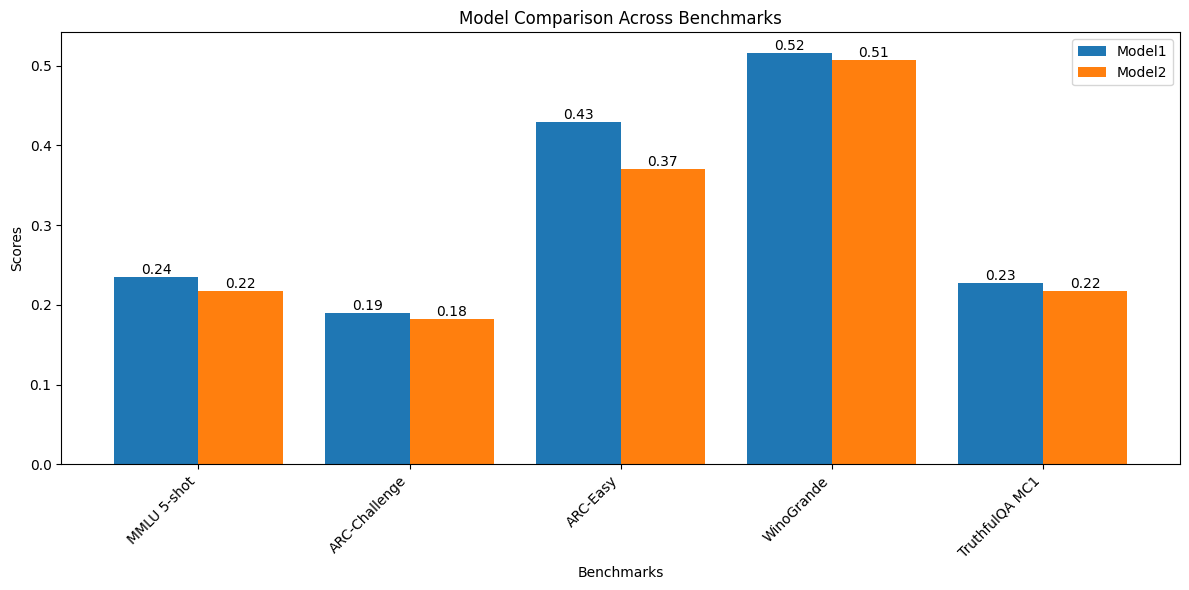

In [32]:
import matplotlib.pyplot as plt   # dua import yang tidak ada di listing buku
import pandas as pd


def compare_models(model1_scores, model2_scores, benchmarks):   # persis buku
    df = pd.DataFrame({
        'Model1': model1_scores,
        'Model2': model2_scores
    }, index=benchmarks)
    ax = df.plot(kind='bar', figsize=(12, 6), width=0.8)
    plt.title('Model Comparison Across Benchmarks')
    plt.xlabel('Benchmarks')
    plt.ylabel('Scores')
    plt.legend(['Model1', 'Model2'])
    plt.xticks(rotation=45, ha='right')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f')
    plt.tight_layout()
    plt.show()


real_benchmarks = list(BENCH)
compare_models([RESULTS[b]["fp32"].mean() for b in real_benchmarks],      # Model1 = GPT-2 fp32
               [RESULTS[b]["student"].mean() for b in real_benchmarks],   # Model2 = student 6 layer
               real_benchmarks)

**Grafik ini membuat fp32 tampak unggul atas student.** Tapi tiga hal penting tidak ada:

- **garis tebakan acak:** WinoGrande 0,52 tampak tertinggi, padahal setara lempar koin;
- **ketidakpastian:** tanpa interval, grafik tidak bisa memberi tahu bahwa selisih sekitar 0,07 di ARC-Easy nyata, sedangkan selisih sekitar 0,01 di benchmark lain tidak bisa dibedakan dari noise;
- **nama model:** kolom dikunci `'Model1'`/`'Model2'`, jadi hanya dua model.

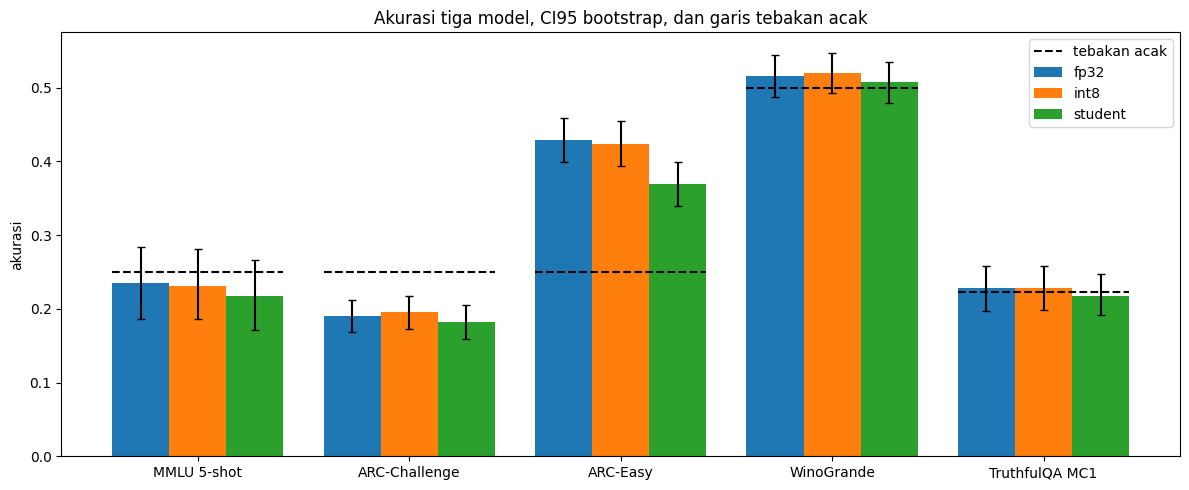

In [33]:
# Data yang sama + tiga hal yang absen di grafik buku: model ketiga, CI95, dan garis tebakan acak
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(real_benchmarks))
width = 0.27
for j, name in enumerate(MODELS):
    stats = np.array([boot_ci(RESULTS[b][name]) for b in real_benchmarks])     # kolom: rata-rata, bawah, atas
    errors = [stats[:, 0] - stats[:, 1], stats[:, 2] - stats[:, 0]]
    ax.bar(x + (j - 1) * width, stats[:, 0], width, yerr=errors, capsize=3, label=name)
for i, b in enumerate(real_benchmarks):
    chance = np.mean([1 / len(s) for s in SCORES[b]["fp32"]])
    ax.hlines(chance, i - 1.5 * width, i + 1.5 * width, colors="black", linestyles="--",
              label="tebakan acak" if i == 0 else None)
ax.set_xticks(x, real_benchmarks)
ax.set_ylabel("akurasi")
ax.set_title("Akurasi tiga model, CI95 bootstrap, dan garis tebakan acak")
ax.legend()
plt.tight_layout()
plt.show()

**Inilah jawaban UTH-3.** MMLU, WinoGrande, dan TruthfulQA berdiri tepat di garis acaknya; ARC-Challenge di bawahnya; hanya ARC-Easy yang jelas di atas. Keunggulan fp32 tinggal satu jarak yang mencolok, di ARC-Easy: fp32 0,429 lawan student 0,361. Ujung kedua intervalnya berdekatan, jadi grafik saja belum bisa memastikan jarak itu nyata; uji berpasangan di UTH-4 yang memutuskan. int8 sejajar fp32 di mana-mana.

**Ini bukan bukti kompresi gratis.** Di empat dari lima benchmark, GPT-2 asli sendiri belum punya kemampuan yang diukur, jadi tak ada yang bisa hilang. Val loss tetap peka karena ia mengukur sesuatu yang selalu dimiliki LM: menebak token berikutnya.

### UTH-4: selisih yang bisa dipercaya

Melihat apakah dua interval bersentuhan hanyalah uji kasar. Karena ketiga model menjawab soal yang *sama*, selisihnya bisa diuji langsung dengan **bootstrap berpasangan**: soal di-resample bersama untuk kedua model, sehingga variasi kesulitan soal tidak terhitung sebagai noise. Tiap selisih mendapat CI95 dan **p-value**, yaitu seberapa sering selisih sebesar itu muncul bila kedua model sebenarnya sama kuat.

Selain akurasi, kita uji skor kontinu dari forward yang sama, **log p(jawaban benar)**: skor opsi diubah menjadi peluang yang jumlahnya 1, lalu diambil log peluang jawaban benar (0 = yakin penuh). Tiap kolom menguji sepuluh selisih sekaligus, jadi `*` baru diberikan bila p-value tetap di bawah 0,05 setelah **koreksi Holm**, yang menaikkan p-value sesuai jumlah perbandingan.

In [34]:
# Statistik di CPU: SCORES berisi angka Python, jadi bootstrap dan koreksi Holm memakai NumPy
def gold_logp(bench, name):
    """log p(jawaban benar) setelah skor dinormalisasi atas opsi soal itu: 0 = yakin benar, makin negatif makin ragu."""
    items = BENCH[bench][1]
    return np.array([s[item[-1]] - np.logaddexp.reduce(s)
                     for s, item in zip(map(np.asarray, SCORES[bench][name]), items)])


def paired_bootstrap(a, b, n_boot=5000, seed=0):
    """Selisih rata-rata b - a: nilai, CI95, dan p-value dua sisi. Soal yang sama di-resample bersama."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(a), (n_boot, len(a)))
    diffs = (b[idx] - a[idx]).mean(axis=1)
    p = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
    return (b - a).mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5), p


def holm(pvalues):
    """Koreksi Holm: p-value dinaikkan karena banyak perbandingan diuji sekaligus."""
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    adjusted = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out


pairs = [(bench, name) for bench in BENCH for name in ("int8", "student")]
acc = [paired_bootstrap(RESULTS[b]["fp32"], RESULTS[b][m]) for b, m in pairs]
logp = [paired_bootstrap(gold_logp(b, "fp32"), gold_logp(b, m)) for b, m in pairs]
acc_p = holm([r[3] for r in acc])
logp_p = holm([r[3] for r in logp])


def show(result, p_holm, scale=1, digits=1):
    diff, lo, hi, _ = result
    mark = " *" if p_holm < 0.05 else ""
    return f"{diff * scale:+.{digits}f} [{lo * scale:+.{digits}f}, {hi * scale:+.{digits}f}]{mark}"


rows = [{"benchmark": b, "model": m,
         "keputusan sama": f"{np.mean(RESULTS[b][m] == RESULTS[b]['fp32']):.0%}",
         "selisih akurasi (poin %)": show(acc[i], acc_p[i], scale=100),
         "selisih log p(benar)": show(logp[i], logp_p[i], digits=3)}
        for i, (b, m) in enumerate(pairs)]
print("selisih terhadap fp32 dengan CI95 bootstrap berpasangan; * = signifikan setelah koreksi Holm (p < 0.05)")
print(pd.DataFrame(rows).to_string(index=False))

selisih terhadap fp32 dengan CI95 bootstrap berpasangan; * = signifikan setelah koreksi Holm (p < 0.05)
     benchmark   model keputusan sama selisih akurasi (poin %)      selisih log p(benar)
   MMLU 5-shot    int8            91%        -0.4 [-3.9, +3.2]   +0.034 [+0.006, +0.062]
   MMLU 5-shot student            68%        -1.8 [-8.4, +4.6] -0.193 [-0.317, -0.074] *
 ARC-Challenge    int8            95%        +0.5 [-0.7, +1.7]   -0.046 [-0.092, -0.003]
 ARC-Challenge student            85%        -0.9 [-3.0, +1.3] -1.416 [-1.641, -1.199] *
      ARC-Easy    int8            95%        -0.5 [-2.0, +0.9] -0.052 [-0.088, -0.016] *
      ARC-Easy student            79%      -5.9 [-8.7, -3.1] * -1.085 [-1.269, -0.907] *
    WinoGrande    int8            88%        +0.4 [-1.6, +2.3]   -0.006 [-0.014, +0.002]
    WinoGrande student            61%        -0.9 [-4.3, +2.7] -0.085 [-0.123, -0.047] *
TruthfulQA MC1    int8            97%        +0.0 [-1.1, +1.1]   -0.042 [-0.108, +0.024]
Truthf

- **Keputusan sama:** int8 membalik 2-13% keputusan benar/salah fp32 (terbanyak di WinoGrande, tempat model nyaris 50:50), tapi balikan itu saling meniadakan sehingga akurasinya tampak sama. Student membalik jauh lebih banyak, sekitar 10-40%.
- **Selisih akurasi:** hanya student di ARC-Easy (sekitar -7 poin) yang signifikan.
- **Selisih log p(jawaban benar):** student signifikan di hampir semua benchmark, int8 paling banyak di satu atau dua benchmark. Di TruthfulQA, selisih sekitar -3,7 berarti peluang jawaban benar turun kira-kira $e^{3{,}7} \approx 40$ kali (rata-rata geometrik), padahal akurasinya nyaris tidak bergeser.

Interval di tabel belum dikoreksi Holm, jadi interval yang tidak memuat nol belum tentu signifikan. Contohnya student di MMLU: -0,123 [-0,241; -0,008] tidak memuat nol, tapi tidak lolos koreksi. Ujung interval setipis itu bisa jatuh ke sisi mana pun di run lain, jadi untuk memutuskan signifikan atau tidak, pegangannya tanda `*`.

**Pelajaran praktisnya:** simpan skor per opsi, bukan hanya benar/salah. Skor itu keluar dari perhitungan yang sama tanpa biaya tambahan, dan jauh lebih peka.

Fungsi terakhir buku menerjemahkan dua deret skor menjadi kalimat. Ia jalan apa adanya; kita pakai pada skor contoh dari buku sendiri.

In [35]:
# Skor contoh dan interpret_results persis buku
model1_scores = [0.75, 0.82, 0.68, 0.70, 0.77, 0.65, 0.80]
model2_scores = [0.80, 0.79, 0.72, 0.75, 0.81, 0.68, 0.78]
benchmarks = ['MMLU', 'SuperGLUE', 'TruthfulQA', 'ARC', 'GSM8K',
              'HumanEval', 'WinoGrande']


def interpret_results(model1_scores, model2_scores, benchmarks):
    for benchmark, score1, score2 in zip(
        benchmarks, model1_scores, model2_scores
    ):
        print(f"\n{benchmark}:")
        print(f"Model1: {score1:.2f}, Model2: {score2:.2f}")
        if score1 > score2:
            print(f"Model1 outperforms Model2 by {(score1 - score2) * 100:.2f}%")
        elif score2 > score1:
            print(f"Model2 outperforms Model1 by {(score2 - score1) * 100:.2f}%")
        else:
            print("Both models perform equally")
        if benchmark == 'MMLU':
            print("This indicates overall language understanding across diverse subjects.")
        elif benchmark == 'GSM8K':
            print("This reflects mathematical reasoning capabilities.")
        # Add similar interpretations for other benchmarks
interpret_results(model1_scores, model2_scores, benchmarks)


MMLU:
Model1: 0.75, Model2: 0.80
Model2 outperforms Model1 by 5.00%
This indicates overall language understanding across diverse subjects.

SuperGLUE:
Model1: 0.82, Model2: 0.79
Model1 outperforms Model2 by 3.00%

TruthfulQA:
Model1: 0.68, Model2: 0.72
Model2 outperforms Model1 by 4.00%

ARC:
Model1: 0.70, Model2: 0.75
Model2 outperforms Model1 by 5.00%

GSM8K:
Model1: 0.77, Model2: 0.81
Model2 outperforms Model1 by 4.00%
This reflects mathematical reasoning capabilities.

HumanEval:
Model1: 0.65, Model2: 0.68
Model2 outperforms Model1 by 3.00%

WinoGrande:
Model1: 0.80, Model2: 0.78
Model1 outperforms Model2 by 2.00%


**Persen yang bukan persen.** `(score2 - score1) * 100` adalah selisih **poin persentase**: 0,75 -> 0,80 dicetak "5.00%", padahal relatifnya 6,7%; 0,20 -> 0,25 juga "5.00%", padahal relatifnya 25%. Lebih mendasar lagi, fungsi ini mengumumkan "outperforms" untuk selisih sekecil apa pun, tanpa melihat jumlah soal. Jadi pertanyaan yang benar untuk tujuh selisih ini: mana yang lebih besar dari goyangan wajar untuk jumlah soal benchmark-nya?

In [36]:
def two_proportion_test(p1, p2, n):
    """Uji z dua proporsi independen dengan n soal per model: p-value dua sisi dan MDE (power 80%, alfa 5%)."""
    pooled = (p1 + p2) / 2
    se = math.sqrt(2 * pooled * (1 - pooled) / n)
    z = (p2 - p1) / se
    return math.erfc(abs(z) / math.sqrt(2)), (1.96 + 0.84) * se


# jumlah soal benchmark yang dirujuk skor contoh buku (SuperGLUE = 56 soal validasi CB di listing; TruthfulQA = 817 di paper)
BOOK_N = {"MMLU": 14042, "SuperGLUE": 56, "TruthfulQA": 817, "ARC": 1172, "GSM8K": 1319, "HumanEval": 164, "WinoGrande": 1267}
rows = []
for bench, s1, s2 in zip(benchmarks, model1_scores, model2_scores):
    p_value, mde = two_proportion_test(s1, s2, BOOK_N[bench])
    rows.append({"benchmark": bench, "soal": BOOK_N[bench], "selisih (poin %)": f"{(s2 - s1) * 100:+.1f}",
                 "relatif": f"{(s2 - s1) / s1:+.1%}", "p": f"{p_value:.3f}", "MDE (poin %)": f"{mde * 100:.1f}",
                 "putusan": "signifikan" if p_value < 0.05 else "tidak signifikan"})
print(pd.DataFrame(rows).to_string(index=False))

 benchmark  soal selisih (poin %) relatif     p MDE (poin %)          putusan
      MMLU 14042             +5.0   +6.7% 0.000          1.4       signifikan
 SuperGLUE    56             -3.0   -3.7% 0.689         21.0 tidak signifikan
TruthfulQA   817             +4.0   +5.9% 0.078          6.3 tidak signifikan
       ARC  1172             +5.0   +7.1% 0.007          5.2       signifikan
     GSM8K  1319             +4.0   +5.2% 0.012          4.4       signifikan
 HumanEval   164             +3.0   +4.6% 0.565         14.6 tidak signifikan
WinoGrande  1267             -2.0   -2.5% 0.216          4.5 tidak signifikan


Skor contoh buku dibayangkan sebagai hasil sungguhan dengan jumlah soal di kolom `soal`. Untuk dua model yang masing-masing menjawab $n$ soal dengan akurasi rata-rata $\bar a$, *standard error* selisihnya kira-kira $\sqrt{2\bar a(1-\bar a)/n}$. Dari situ lahir p-value versi rumus dan **MDE** (*minimum detectable effect*, $2{,}8$ kali *standard error*): selisih sungguhan yang akan terdeteksi signifikan dengan peluang 80%.

Tiga dari tujuh signifikan: MMLU dengan 14.042 soal (MDE 1,4 poin), lalu ARC dan GSM8K, yang selisihnya hampir sebesar MDE-nya. MDE adalah resolusi benchmark, bukan ambang signifikansi: HumanEval dengan 164 soal baru andal menangkap selisih sekitar 14,6 poin, dan 56 soal CB di listing sekitar **21 poin**. "Outperforms by 3.00%" di 164 soal tidak bisa dibedakan dari noise. Rumus ini mengandaikan soal yang berbeda; untuk soal yang sama, bootstrap berpasangan biasanya lebih tajam.

In [37]:
print(f"total waktu sejak sel lingkungan: {(time.time() - T_START) / 60:.1f} menit")
if DEVICE.type == "cuda":
    print(f"puncak memori GPU: {torch.cuda.max_memory_allocated(DEVICE) / 2**30:.1f} GiB")

total waktu sejak sel lingkungan: 22.5 menit
puncak memori GPU: 3.5 GiB


## Summary

**Uji metrik sebelum menguji model.** Metrik GSM8K buku memberi 0% kepada solusi resmi; metrik substring TruthfulQA memberi 12,2% kepada "I have no comment."; harness HumanEval baru dipakai setelah lulus uji orakel dua arah.

**Evaluasi tanpa training bukan evaluasi.** Listing SuperGLUE, ARC, dan WinoGrande menilai kepala BERT acak; di CB, seed menentukan "akurasi" 0,089 atau 0,500.

**Skor butuh garis acak, interval, dan aturan skor yang disebut.** GPT-2 124M setara menebak di MMLU, TruthfulQA MC1, dan WinoGrande, dan di bawah acak di ARC-Challenge karena jumlah log-prob menghukum opsi panjang.

**Kompresi nyaris tak terlihat oleh akurasi.** Akurasi hanya memisahkan student di ARC-Easy, sedangkan log p(jawaban benar) menangkap student di hampir semua benchmark.

**Selisih butuh ukuran.** "Outperforms by 5.00%" adalah 5 poin persentase, dan 56 soal CB baru andal menangkap selisih sekitar 21 poin.

### What comes next

Bab ini menilai model pada satu potongan data tetap -- satu split, satu prompt, satu set contoh few-shot -- dan melihat seberapa lebar interval yang ditinggalkannya. Chapter 15 membahas **cross-validation untuk LLM**: membangun split yang layak untuk pre-training dan fine-tuning, serta strategi evaluasi few-shot dan zero-shot.